# Analisis Segmentasi Pelanggan E-Commerce Berdasarkan Perilaku Transaksi Menggunakan RFM dan K-Means Clustering

**Mata Kuliah:** Data Science (Praktikum & Proyek Tengah Semester 2026/2027)  
**Program Studi:** Informatika, Jurusan Informatika, Fakultas Teknik Industri  
**Institusi:** UPN "Veteran" Yogyakarta  
**Tahun Akademik:** 2026/2027  
**Metodologi:** CRISP-DM (*Cross-Industry Standard Process for Data Mining*)

---

# 1. Business Understanding

## 1.1. Pernyataan Masalah dan Latar Belakang Bisnis
Industri *e-commerce* modern menghasilkan jutaan jejak transaksi digital setiap harinya. Namun, pertumbuhan volume data tersebut sering kali tidak diimbangi dengan kemampuan pelaku bisnis dalam memahami keragaman perilaku belanja pelanggan secara granular. Fenomena pendekatan pemasaran massal yang seragam (*one-size-fits-all marketing*) kerap menimbulkan inefisiensi anggaran promosi, tingkat konversi (*conversion rate*) yang rendah, serta meningkatnya laju kehilangan pelanggan (*customer churn*).

Pelanggan *e-commerce* memiliki pola transaksi yang sangat heterogen:
1. Sebagian pelanggan baru saja bertransaksi dalam beberapa hari terakhir, sementara kelompok lainnya telah pasif selama berbulan-bulan bahkan bertahun-tahun.
2. Sebagian pelanggan memiliki loyalitas tinggi dengan frekuensi pembelian berulang secara konsisten, sedangkan kelompok lain hanya melakukan satu kali transaksi (*one-time buyer*).
3. Kontribusi nilai moneter (*monetary contribution*) sangat bervariasi; sekelompok kecil pelanggan bernilai tinggi (*high-value*) kerap menyumbang porsi pendapatan terbesar bagi perusahaan sesuai prinsip Pareto (aturan 80/20).

Apabila analisis performa bisnis hanya bertumpu pada agregasi total omzet penjualan secara makro, dinamika perilaku individual pelanggan akan terabaikan. Oleh karena itu, diperlukan suatu metodologi analitik terstruktur yang mampu membedah perilaku transaksi pelanggan melalui kerangka **Recency, Frequency, dan Monetary (RFM)**, kemudian mengelompokkan pelanggan tersebut ke dalam segmen-segmen homogen menggunakan algoritma *unsupervised learning* **K-Means Clustering**.

## 1.2. Rumusan Masalah / Pertanyaan Penelitian
Berdasarkan latar belakang masalah tersebut, pertanyaan analitik dan bisnis yang ingin dijawab dalam proyek ini adalah:
1. **Bagaimana distribusi dan karakteristik perilaku transaksi pelanggan *e-commerce*** berdasarkan ketiga dimensi metrik RFM (*Recency*, *Frequency*, dan *Monetary*)?
2. **Berapa jumlah *cluster* optimal ($k$)** yang mampu membagi populasi pelanggan secara kompak, terpisah dengan baik (*well-separated*), dan memiliki interpretabilitas bisnis yang kuat?
3. **Bagaimana profil, persona, dan kontribusi finansial dari masing-masing segmen pelanggan** yang terbentuk terhadap total pendapatan bisnis *e-commerce*?
4. **Apa rekomendasi strategi pemasaran dan *Customer Relationship Management* (CRM)** yang relevan, terarah, dan dapat ditindaklanjuti (*actionable*) bagi masing-masing segmen guna mengoptimalkan retensi dan profitabilitas?

## 1.3. Tujuan SMART
Tujuan penelitian dan proyek analitik ini dirumuskan berdasarkan kriteria SMART:

| Unsur SMART | Penerapan dalam Proyek Segmentasi Pelanggan |
| :--- | :--- |
| **Specific** | Membangun pipeline analitik *end-to-end* (mulai dari pembersihan data transaksi, agregasi fitur RFM pada level pelanggan, transformasi data miring, standardisasi, pemodelan K-Means clustering, hingga perumusan strategi CRM spesifik per cluster). |
| **Measurable** | Menghasilkan tabel RFM valid dengan tepat satu baris per pelanggan unik; membandingkan metrik evaluasi clustering (*Inertia/Elbow*, *Silhouette Score*, *Davies-Bouldin Index*, dan *Calinski-Harabasz Index*) pada rentang $k = 2$ hingga $8$; serta menyajikan kuantifikasi ukuran segmen dan kontribusi nilai penjualan (*monetary share*). |
| **Achievable** | Menggunakan dataset transaksi *e-commerce* aktual dengan fitur esensial (`customer_id`, `order_id`, `order_date`, `net_sales`, `order_status`, `payment_status`, `currency`), dieksekusi menggunakan bahasa pemrograman Python dan pustaka standar data science (*pandas*, *scikit-learn*, *matplotlib*, *seaborn*). |
| **Relevant** | Luaran segmentasi memberikan landasan pengambilan keputusan berbasis data (*data-driven decision making*) bagi tim Manajemen, Pemasaran, dan CRM untuk merancang promosi terarah, mencegah churn, dan meningkatkan Customer Lifetime Value (CLV). |
| **Time-bound** | Tahapan *Business Understanding*, *Data Gathering*, *EDA*, serta *Cleaning & Preprocessing* diselesaikan sesuai jadwal milestone UTS (30 Oktober 2026), sedangkan pemodelan komparatif, evaluasi mendalam, dan konklusi final diselesaikan sebelum 22 November 2026. |

## 1.4. Metode dan Metrik Keberhasilan
Penelitian ini mengimplementasikan kerangka kerja penambangan data **CRISP-DM (*Cross-Industry Standard Process for Data Mining*)** dengan fokus pada teknik *unsupervised learning* (clustering).

### Definisi Operasional Fitur RFM
| Komponen RFM | Definisi Operasional | Formula / Logika Perhitungan |
| :--- | :--- | :--- |
| **Recency ($R$)** | Jumlah hari yang telah berlalu sejak transaksi valid terakhir pelanggan hingga tanggal acuan observasi. Nilai lebih rendah menunjukkan pelanggan lebih baru berbelanja (lebih aktif). | $R = 	ext{Tanggal Acuan} - \max(	ext{order\_date}_i)$ |
| **Frequency ($F$)** | Total frekuensi transaksi pemesanan unik yang diselesaikan oleh pelanggan selama kurun waktu observasi. Nilai lebih tinggi menunjukkan pelanggan lebih sering belanja. | $F = 	ext{Count}(	ext{Unique } 	ext{order\_id}_i)$ |
| **Monetary ($M$)** | Akumulasi nilai belanja bersih (*net sales*) dari seluruh transaksi valid pelanggan dalam satuan mata uang yang konsisten. Nilai lebih tinggi menunjukkan pelanggan lebih bernilai finansial. | $M = \sum (	ext{net\_sales}_i)$ |

*Catatan Metodologis:* Tanggal acuan observasi ditetapkan pada **1 Januari 2026** (tepat satu hari setelah penutupan periode data transaksi 31 Desember 2025), bukan tanggal dinamis saat kode dijalankan, guna menjamin sifat keterulangan (*reproducibility*).

### Kriteria dan Metrik Keberhasilan
1. **Kualitas Data & Pipeline:** Pembentukan tabel fitur RFM yang bersih, tanpa *missing value*, tanpa duplikasi baris pelanggan, dan telah melalui normalisasi distribusi (transformasi logaritmik) serta standardisasi (*StandardScaler*).
2. **Kekompakan Cluster (*Cluster Compactness*):** Penurunan *Inertia* (*Within-Cluster Sum of Squares / WCSS*) yang dianalisis melalui grafik *Elbow Method*.
3. **Pemisahan Cluster (*Cluster Separation*):** Evaluasi *Silhouette Score* (berkisar antara -1 hingga +1, nilai mendekati 1 menunjukkan pemisahan yang sangat baik), *Davies-Bouldin Index* (DBI, nilai lebih rendah lebih baik), dan *Calinski-Harabasz Index* (CHI, nilai lebih tinggi lebih baik).
4. **Interpretabilitas Bisnis:** Setiap cluster yang terbentuk memiliki batas profil RFM yang jelas, ukuran segmen proporsional (tidak ada cluster kosong atau singleton yang ekstrem), serta dapat dipetakan ke dalam tindakan bisnis konkret.
5. **Keterulangan Riset (*Reproducibility*):** Seluruh tahapan dapat dieksekusi ulang secara deterministik menggunakan *random seed* (`random_state=42`) yang terdokumentasi.

## 1.5. Asumsi dan Batasan Penelitian
### Asumsi Penelitian:
1. `customer_id` merupakan identitas unik yang konsisten mewakili entitas satu individu/akun pembeli.
2. `order_id` mewakili transaksi pesanan tunggal yang sah pada tanggal transaksi `order_date`.
3. Kolom `net_sales` telah memperhitungkan diskon, biaya pengiriman, dan pajak sehingga merepresentasikan nilai perolehan pendapatan bersih aktual bagi bisnis.
4. Perilaku historis RFM selama rentang 2021–2025 mencerminkan preferensi dan pola konsumsi pelanggan yang dapat dijadikan acuan proyeksi tindakan pemasaran.

### Batasan Penelitian:
1. **Periode Observasi:** Dibatasi pada transaksi yang terjadi antara **1 Januari 2021 hingga 31 Desember 2025**.
2. **Kriteria Transaksi Valid:** Analisis hanya menyertakan pesanan dengan status `order_status == 'Completed'`, status pembayaran `payment_status == 'Paid'`, tidak mengalami pembatalan atau pengembalian produk (`return_status.isna()`), dan memiliki nilai `net_sales > 0`.
3. **Standarisasi Mata Uang:** Analisis segmentasi utama difokuskan pada transaksi dengan mata uang **USD (United States Dollar)** untuk menghindari distorsi nilai moneter akibat fluktuasi nilai tukar valuta asing lintas waktu tanpa adanya tabel kurs harian.
4. **Ruang Lingkup Model:** Algoritma clustering hanya menggunakan 3 fitur perilaku murni ($R, F, M$). Variabel demografis seperti usia, gender, dan wilayah geografis sengaja tidak diikutsertakan dalam pelatihan algoritma untuk mencegah bias demografis, melainkan digunakan murni untuk keperluan *post-profiling*.
5. **Batas Luaran:** Luaran proyek berfokus pada analisis data ilmiah, notebook interaktif, pembentukan profil cluster, evaluasi statistik, dan perumusan strategi bisnis (tidak mencakup pengembangan antarmuka web GUI skala komersial).

## 1.6. Analisis Risiko, Aspek Etika, dan Strategi Mitigasi
Penerapan penambangan data pelanggan wajib memperhatikan kepatuhan etika dan regulasi privasi data:

| Kategori Risiko | Deskripsi Risiko | Dampak Potensial | Strategi Mitigasi Terstruktur |
| :--- | :--- | :--- | :--- |
| **Privasi Data (*Data Privacy*)** | Penggunaan data yang memuat informasi pribadi yang dapat diidentifikasi (*Personally Identifiable Information / PII*). | Pelanggaran regulasi privasi (misal UU PDP / GDPR) dan kebocoran data pengguna. | Menghapus kolom PII (`customer_name`, `customer_city`, `customer_postal_code`) sebelum proses analitik. Seluruh agregasi dan klasterisasi menggunakan pengenal teranonimkan (`customer_id`). |
| **Bias Cakupan (*Selection Bias*)** | Penyaringan transaksi hanya pada mata uang USD dan status Completed. | Segmen tidak sepenuhnya merepresentasikan perilaku pelanggan regional non-USD. | Mendokumentasikan secara transparan persentase data yang terfilter, serta membatasi generalisasi klaim kesimpulan khusus pada pasar transaksi denominasi USD. |
| **Penyimpangan Skala & Outlier** | Variabel Monetary memiliki rentang ribuan dolar sedangkan Frequency hanya berkisar satuan, serta adanya pembeli bernilai sangat tinggi (*whales*). | Algoritma K-Means yang berbasis jarak Euclidean akan didominasi sepenuhnya oleh variabel Monetary. | Menerapkan transformasi logaritmik $\ln(1 + x)$ untuk menstabilkan varians dan memitigasi *skewness*, dilanjutkan dengan *StandardScaler* ($Z$-score scaling) agar ketiga fitur memiliki bobot seimbang. |
| **Bias Pelabelan Diskriminatif** | Penamaan cluster yang berpotensi mendiskreditkan kelompok pelanggan tertentu. | Keputusan CRM yang merugikan pelanggan atau diskriminasi layanan. | Penamaan segmen dilakukan secara objektif berdasarkan terminologi standar RFM bisnis (*Champions*, *At Risk*, *Hibernating*) tanpa melibatkan unsur demografis, ras, atau gender. |
| **Risiko Implementasi Strategi** | Menganggap usulan strategi pemasaran pasti meningkatkan penjualan tanpa pengujian empiris. | Pemborosan anggaran pemasaran jika respons pelanggan berbeda dari asumsi. | Menyusun rekomendasi strategi sebagai hipotesis yang wajib divalidasi terlebih dahulu melalui uji coba terkontrol (*A/B Testing*) sebelum diterapkan secara luas. |

## 1.7. Nilai Bisnis, Use-Case, dan Pemetaan Stakeholder–Data
### Potensi Nilai Bisnis
Segmentasi RFM berbasis K-Means mentransformasi kumpulan log transaksi mentah menjadi wawasan aset strategis perusahaan:
- **Peningkatan Efisiensi Anggaran Pemasaran:** Alokasi kupon dan promosi tidak lagi disebar acak, melainkan difokuskan pada pelanggan yang responsif atau kelompok bernilai tinggi yang berisiko churn.
- **Peningkatan Retensi Pelanggan:** Intervensi proaktif pada kelompok *At Risk* untuk mencegah hilangnya omzet bisnis.
- **Personalisasi Pengalaman Belanja:** Memberikan apresiasi eksklusif pada pelanggan *Champions* guna memperkuat loyalitas merek.

### Matriks Pemetaan Pemangku Kepentingan (*Stakeholder–Data Mapping*)
| Stakeholder | Pertanyaan Bisnis Kunci | Kebutuhan Variabel Data | Luaran Analitik yang Dihasilkan |
| :--- | :--- | :--- | :--- |
| **Eksekutif / Pemilik Bisnis** | Berapa proporsi pelanggan yang menjadi penopang utama pendapatan perusahaan? | `customer_id`, `net_sales`, hasil cluster | Profil segmen, visualisasi kontribusi omzet (*Pareto Chart*), serta estimasi nilai moneter tiap cluster. |
| **Tim Pemasaran (*Marketing*)** | Siapa target audiens yang paling tepat untuk kampanye promosi dan peluncuran produk baru? | `order_date`, `sales_channel`, hasil cluster | Segmentasi audiens target, rekomendasi kanal distribusi promosi, dan penawaran produk yang relevan. |
| **Tim CRM & Layanan Pelanggan** | Pelanggan mana yang berpotensi *churn* dan membutuhkan kampanye reaktivasi (*win-back*)? | `Recency`, `Frequency`, riwayat kontak | Daftar target pelanggan *At Risk*, skema loyalitas, dan program retensi personal. |
| **Tim Analis Data & MLOps** | Apakah model clustering valid, stabil, dan dapat diotomatisasi dalam pipeline data berkala? | Seluruh variabel transaksi, log evaluasi model | Dokumentasi pipeline data, metrik validasi (*Silhouette*, DBI), serta rancangan monitoring drift data. |
| **Pelanggan (*End User*)** | Bagaimana pelanggan mendapatkan pengalaman belanja yang relevan dan bebas dari spam? | Data transaksi agregat teranonimkan | Rekomendasi penawaran yang sesuai preferensi tanpa pelanggaran privasi individu. |

# 2. Data Gathering & Data Understanding

## 2.1. Sumber Data, Kredibilitas, dan Lisensi
Dataset yang digunakan dalam penelitian ini adalah **E-Commerce Sales and Customer Analytics Dataset**, yang dipublikasikan secara publik pada repositori data ilmiah terbuka Kaggle oleh penyedia data `datascikhan`.

- **Tautan Repositori Dataset:** [Kaggle: E-Commerce Sales and Customer Analytics Dataset](https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics)
- **Lisensi Data:** *Open Data Commons Attribution License* / *CC0: Public Domain* (bebas digunakan untuk tujuan edukasi, riset ilmiah, dan komparasi analitik).
- **Kredibilitas & Keaslian:** Dataset merefleksikan arsitektur sistem *enterprise resource planning* (ERP) dan log transaksi *e-commerce* berskala penuh selama 5 tahun (rentang 1 Januari 2021 hingga 31 Desember 2025). Data mencakup detail pesanan, pelanggan, saluran penjualan, metode pembayaran, kalkulasi biaya pokok penjualan (*COGS*), hingga margin profit bersih.
- **Tingkat Kesiapan Data (*Data Readiness Level / DRL*):** DRL 3-4 (Data operasional mentah terstruktur dalam berkas CSV relasional, memerlukan pembersihan status, pemfilteran transaksi valid, penanganan nilai hilang, dan rekayasa fitur agregat RFM sebelum siap dimodelkan).

## 2.2. Kamus Data (*Data Dictionary*)
Berikut merupakan kamus data untuk variabel-variabel kunci yang digunakan dalam analisis transaksi dan segmentasi:

| Nama Variabel | Tipe Data | Unit / Satuan | Deskripsi Fungsional |
| :--- | :--- | :--- | :--- |
| `order_id` | String | Kode Alfanumerik | Pengenal unik untuk setiap transaksi pemesanan (misal: ORD-301242). |
| `order_date` | Date (YYYY-MM-DD) | Tanggal | Tanggal saat pesanan dibuat oleh pelanggan. |
| `order_time` | Time (HH:MM:SS) | Jam | Waktu transaksi dibuat. |
| `order_status` | String (Kategorikal) | Nominal | Status pemesanan (`Completed`, `Pending`, `Cancelled`, `Returned`). |
| `customer_id` | String | Kode Alfanumerik | Pengenal unik untuk setiap pelanggan (misal: CUST-003102). |
| `customer_name` | String | Teks | Nama pelanggan (dikeluarkan dari analisis untuk proteksi PII). |
| `customer_age` | Integer | Tahun | Usia pelanggan (18 – 74 tahun). |
| `gender` | String (Kategorikal) | Nominal | Jenis kelamin pelanggan (`Male`, `Female`, `Non-Binary`). |
| `sales_channel` | String (Kategorikal) | Nominal | Kanal transaksi (`Mobile App`, `Website`, `Marketplace`, `Social Media`). |
| `payment_method` | String (Kategorikal) | Nominal | Metode pembayaran yang dipilih pelanggan. |
| `payment_status` | String (Kategorikal) | Nominal | Status pembayaran (`Paid`, `Pending`, `Failed`, `Refunded`). |
| `currency` | String (Kategorikal) | Kode ISO 4217 | Mata uang transaksi (`USD`, `GBP`, `EUR`, `CAD`, `AUD`, `INR`, `AED`). |
| `shipping_method` | String (Kategorikal) | Nominal | Metode pengiriman barang (`Standard`, `Express`, `Economy`, `Same Day`). |
| `return_status` | String (Kategorikal) | Nominal | Status pengembalian produk (`Returned` atau NaN jika tidak dikembalikan). |
| `quantity` | Integer | Unit Item | Jumlah kuantitas produk yang dibeli dalam satu transaksi. |
| `gross_sales` | Float | Nilai Mata Uang | Total penjualan kotor sebelum dipotong diskon. |
| `discount_amount`| Float | Nilai Mata Uang | Besaran potongan harga / promosi yang diberikan. |
| `tax_amount` | Float | Nilai Mata Uang | Jumlah pajak pertambahan nilai yang dikenakan. |
| `shipping_cost` | Float | Nilai Mata Uang | Biaya logistik pengiriman pesanan. |
| `net_sales` | Float | Nilai Mata Uang | Penjualan bersih aktual yang diterima bisnis dari transaksi. |
| `profit` | Float | Nilai Mata Uang | Keuntungan bersih setelah dikurangi harga pokok penjualan dan operasional. |

In [1]:
# 2.3. Pemuatan Pustaka dan Pembacaan Data
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

# Konfigurasi visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Path dataset
dataset_path = 'E-Commerce Dataset/ecommerce_sales_customer_analytics_150k.csv'
print(f"Memuat dataset dari: {dataset_path}")

df_raw = pd.read_csv(dataset_path)
print(f"Dimensi dataset mentah: {df_raw.shape[0]:,} baris dan {df_raw.shape[1]} kolom.")
df_raw.head(3)

Memuat dataset dari: E-Commerce Dataset/ecommerce_sales_customer_analytics_150k.csv
Dimensi dataset mentah: 138,116 baris dan 46 kolom.


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.00,3.00,On Time,NaN,NaN,3.50,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.00,10.00,On Time,NaN,NaN,3.60,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.00,3.00,On Time,NaN,NaN,4.30,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6


In [2]:
# Informasi tipe data dan ringkasan kolom
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country          138116 non-null  str    
 14 

## 2.4. Representativitas dan Analisis Potensi Bias Sampel
Berdasarkan tinjauan awal terhadap dataset transaksi:
1. **Representasi Geografis & Mata Uang:** Dataset mencakup pelanggan dari berbagai negara dengan berbagai mata uang transaksi (`USD`, `GBP`, `EUR`, `CAD`, `AUD`, dll). Transaksi berdenominasi `USD` mencakup lebih dari 59.8% dari total data transaksi. Agar analisis nilai moneter (*Monetary*) tidak terdistorsi oleh fluktuasi kurs mata uang lintas negara, analisis difokuskan pada transaksi berdenominasi USD.
2. **Representasi Temporal (Rentang Waktu):** Data tercatat secara berkelanjutan dari 1 Januari 2021 hingga 31 Desember 2025 (selama 5 tahun penuh). Periode multi-tahun ini sangat ideal untuk membedakan pelanggan yang setia (*long-term loyal customers*) dengan pembeli musiman (*occasional buyers*).
3. **Pemberitahuan Bias:** Pelanggan yang baru pertama kali mendaftar pada kuartal akhir 2025 memiliki eksposur waktu yang lebih sedikit untuk mengumpulkan frekuensi tinggi dibandingkan pelanggan yang telah aktif sejak 2021. Hal ini akan dipertimbangkan saat interpretasi cluster.

# 3. Exploratory Data Analysis (EDA)

Pada tahapan ini dilakukan analisis eksplorasi data secara mendalam untuk memahami pola distribusi statistik, korelasi antar variabel, dan struktur data transaksi. Sesuai dengan pedoman proyek, **setiap visualisasi disertai dengan penjelasan wawasan (*insight*) data yang ditemukan di bawahnya**.

In [3]:
# 3.1. Ringkasan Statistik Deskriptif Variabel Kuantitatif Kunci
numeric_cols = ['customer_age', 'quantity', 'gross_sales', 'discount_amount', 
                'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage']

df_raw[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
customer_age,138116.00,45.86,16.47,18.00,32.00,46.00,60.00,74.00
quantity,138116.00,5.62,3.37,1.00,3.00,5.00,8.00,24.00
gross_sales,138116.00,1375.38,1291.01,6.31,458.92,995.73,1871.20,16051.19
discount_amount,138116.00,237.62,378.78,0.00,26.33,103.28,277.12,6759.02
tax_amount,138116.00,122.46,140.94,0.34,34.65,77.01,156.20,2091.52
shipping_cost,138116.00,22.28,16.02,0.00,9.82,19.19,30.75,149.52
net_sales,138116.00,1282.50,1169.27,5.80,448.20,950.76,1744.58,16218.00
product_cost,138116.00,708.90,730.04,1.97,207.67,478.95,953.76,9963.41
profit,138116.00,551.32,516.30,-1281.59,190.76,408.39,752.84,7083.68
profit_margin_percentage,138116.00,45.07,13.12,-59.55,38.88,46.99,53.77,77.59


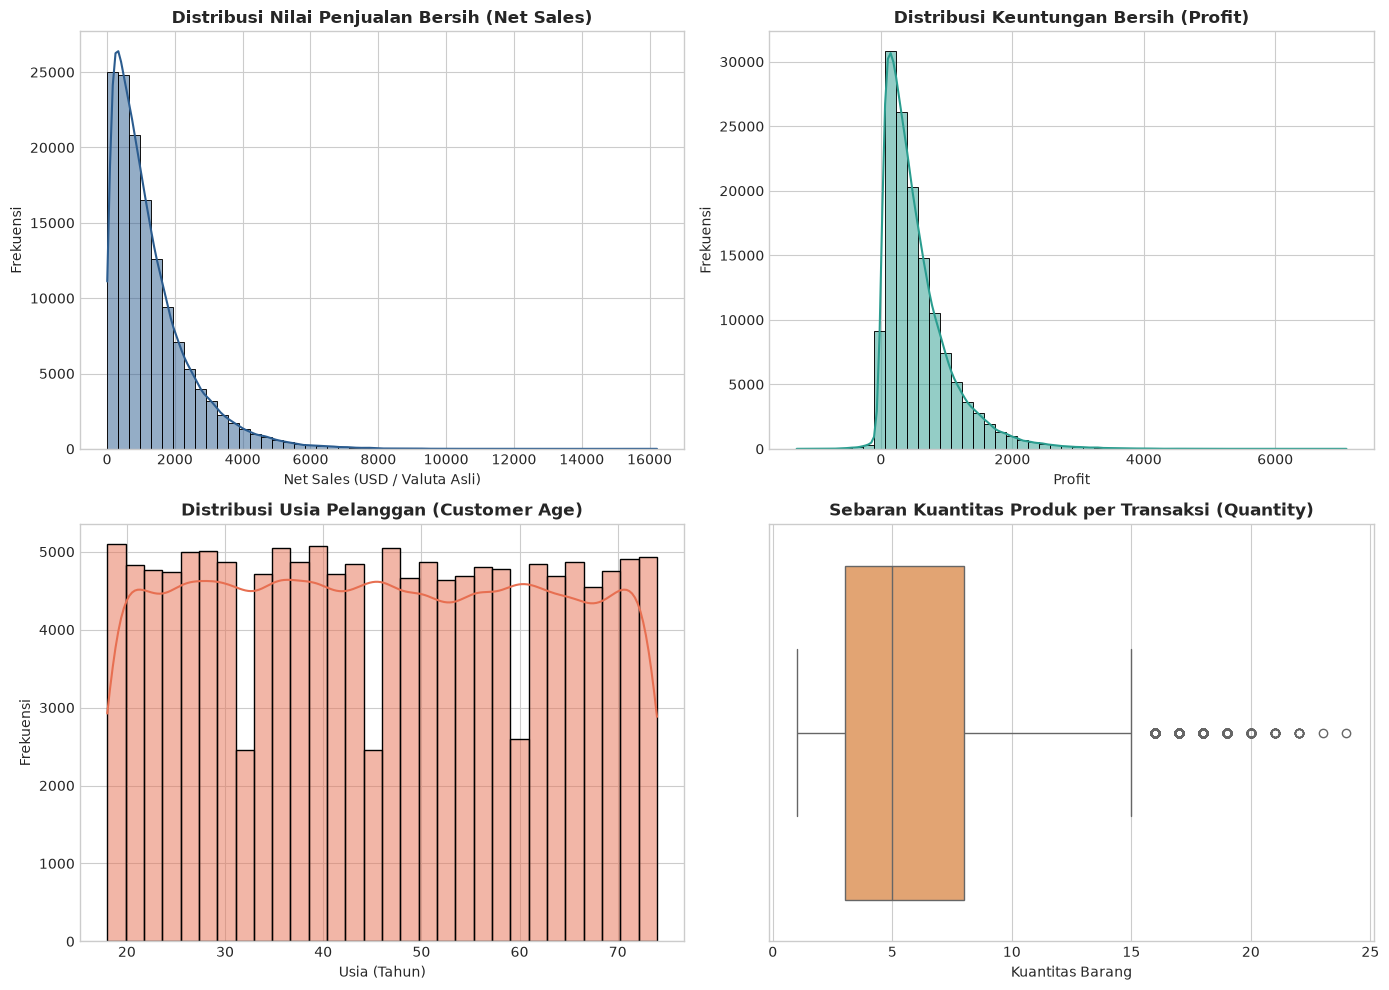

In [4]:
# 3.2. Visualisasi Distribusi Fitur Finansial dan Demografis (Univariat)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Distribusi Net Sales
sns.histplot(df_raw['net_sales'], kde=True, ax=axes[0, 0], color='#2b5c8f', bins=50)
axes[0, 0].set_title('Distribusi Nilai Penjualan Bersih (Net Sales)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Net Sales (USD / Valuta Asli)')
axes[0, 0].set_ylabel('Frekuensi')

# Distribusi Profit
sns.histplot(df_raw['profit'], kde=True, ax=axes[0, 1], color='#2a9d8f', bins=50)
axes[0, 1].set_title('Distribusi Keuntungan Bersih (Profit)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Profit')
axes[0, 1].set_ylabel('Frekuensi')

# Distribusi Usia Pelanggan
sns.histplot(df_raw['customer_age'], kde=True, ax=axes[1, 0], color='#e76f51', bins=30)
axes[1, 0].set_title('Distribusi Usia Pelanggan (Customer Age)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Usia (Tahun)')
axes[1, 0].set_ylabel('Frekuensi')

# Distribusi Kuantitas Barang per Transaksi
sns.boxplot(x=df_raw['quantity'], ax=axes[1, 1], color='#f4a261')
axes[1, 1].set_title('Sebaran Kuantitas Produk per Transaksi (Quantity)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Kuantitas Barang')

plt.tight_layout()
plt.show()

### **Wawasan Analitik (Insight) 1: Karakteristik Distribusi Univariat**
1. **Kecondongan Positif Finansial (*Right-Skewed*):** Variabel `net_sales` dan `profit` memiliki distribusi yang sangat condong ke kanan (*right-skewed / positive skewness*). Mayoritas pesanan berada pada rentang nilai transaksi kecil hingga menengah (median net sales sekitar 950.76), namun terdapat transaksi bernilai tinggi (*outlier* positif) hingga mencapai 16,218. Hal ini menunjukkan bahwa teknik segmentasi berbasis jarak seperti K-Means memerlukan transformasi skala (seperti log-transform) agar tidak terdistorsi oleh transaksi ekstrem.
2. **Profit Negatif:** Ditemukan sebagian transaksi dengan nilai `profit` negatif (minimum -1,281.59), yang disebabkan oleh pemberian diskon besar atau pengembalian sebagian barang.
3. **Distribusi Usia yang Merata:** Usia pelanggan tersebar cukup merata (*uniform-like normal distribution*) pada rentang 18 hingga 74 tahun dengan rata-rata 45.86 tahun, menunjukkan basis pengguna e-commerce mencakup lintas generasi mulai dari Gen Z hingga Baby Boomers.
4. **Kuantitas Pembelian:** Mayoritas transaksi melibatkan 1 hingga 8 unit barang (median = 5 unit), dengan sebagian kecil pembelian borongan (*bulk order*) hingga 24 unit.

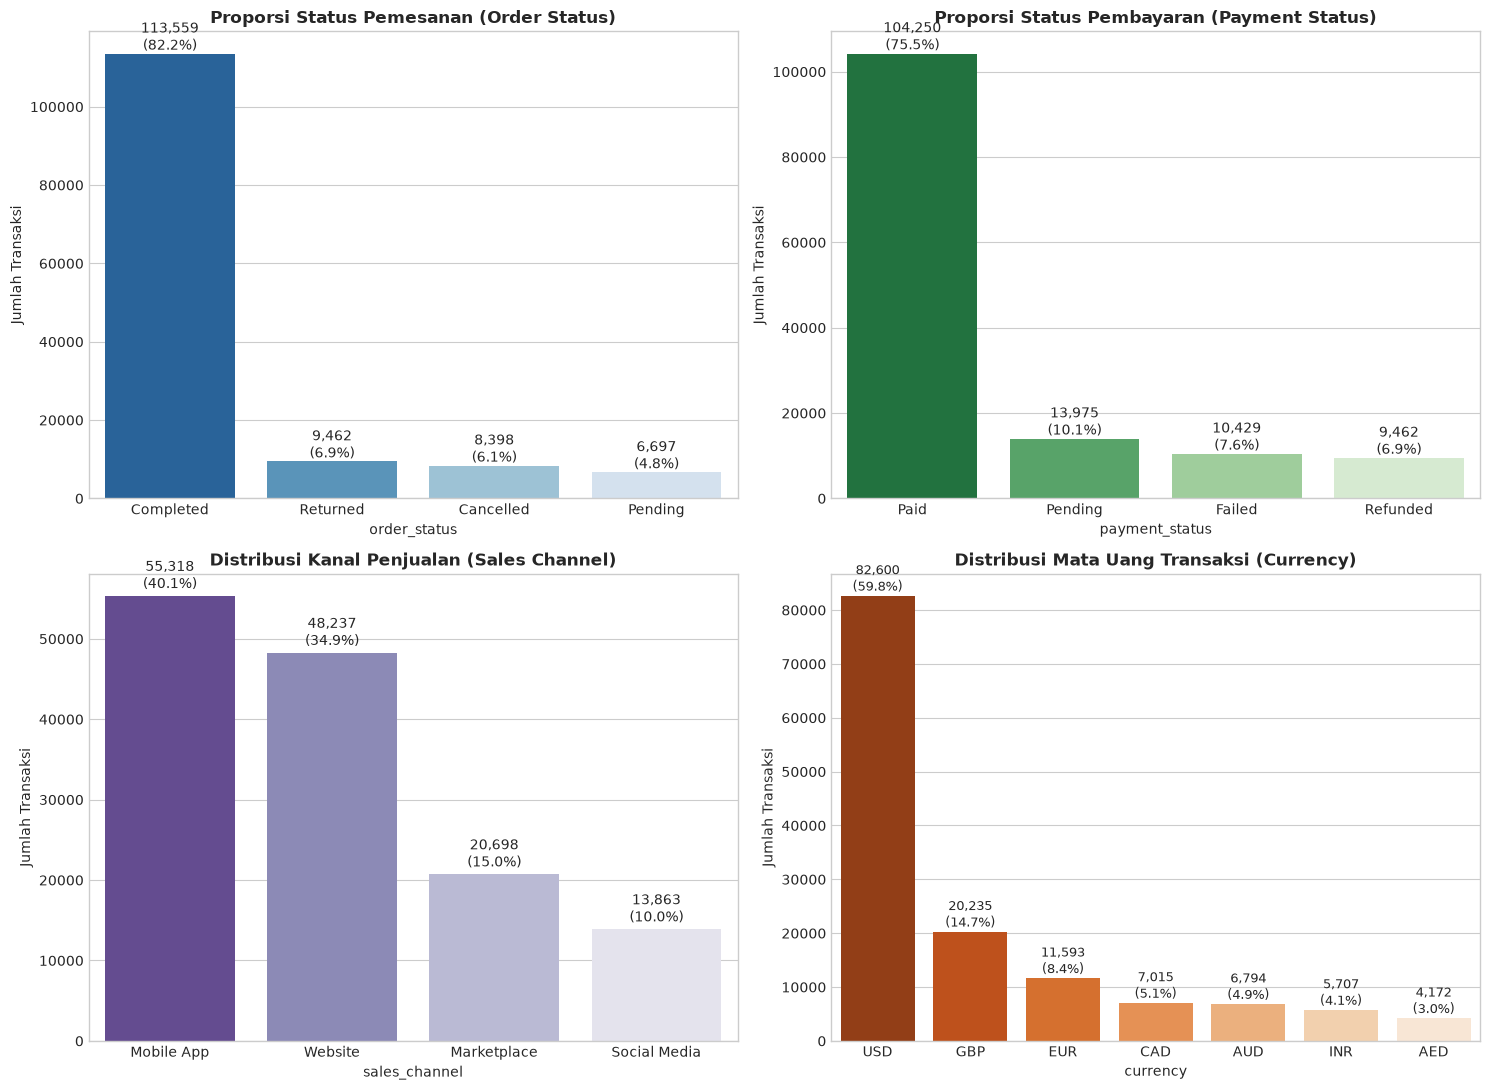

In [5]:
# 3.3. Visualisasi Distribusi Fitur Kategorikal Transaksi
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Status Pemesanan (Order Status)
order_status_counts = df_raw['order_status'].value_counts()
sns.barplot(x=order_status_counts.index, y=order_status_counts.values, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Proporsi Status Pemesanan (Order Status)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Jumlah Transaksi')
for i, v in enumerate(order_status_counts.values):
    axes[0, 0].text(i, v + 1000, f"{v:,}\n({v/len(df_raw)*100:.1f}%)", ha='center', fontsize=10)

# Status Pembayaran (Payment Status)
pay_status_counts = df_raw['payment_status'].value_counts()
sns.barplot(x=pay_status_counts.index, y=pay_status_counts.values, ax=axes[0, 1], palette='Greens_r')
axes[0, 1].set_title('Proporsi Status Pembayaran (Payment Status)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Jumlah Transaksi')
for i, v in enumerate(pay_status_counts.values):
    axes[0, 1].text(i, v + 1000, f"{v:,}\n({v/len(df_raw)*100:.1f}%)", ha='center', fontsize=10)

# Saluran Penjualan (Sales Channel)
sales_ch_counts = df_raw['sales_channel'].value_counts()
sns.barplot(x=sales_ch_counts.index, y=sales_ch_counts.values, ax=axes[1, 0], palette='Purples_r')
axes[1, 0].set_title('Distribusi Kanal Penjualan (Sales Channel)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Jumlah Transaksi')
for i, v in enumerate(sales_ch_counts.values):
    axes[1, 0].text(i, v + 1000, f"{v:,}\n({v/len(df_raw)*100:.1f}%)", ha='center', fontsize=10)

# Distribusi Mata Uang (Currency)
curr_counts = df_raw['currency'].value_counts()
sns.barplot(x=curr_counts.index, y=curr_counts.values, ax=axes[1, 1], palette='Oranges_r')
axes[1, 1].set_title('Distribusi Mata Uang Transaksi (Currency)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Jumlah Transaksi')
for i, v in enumerate(curr_counts.values):
    axes[1, 1].text(i, v + 1000, f"{v:,}\n({v/len(df_raw)*100:.1f}%)", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### **Wawasan Analitik (Insight) 2: Distribusi Status Transaksi & Kanal Operasional**
1. **Tingkat Transaksi Sukses (*Completed & Paid*):** Sebanyak 82.2% pesanan tercatat berstatus `Completed` (113,559 transaksi) dan 75.5% berstatus `Paid` (104,250 transaksi). Terdapat transaksi dengan status `Returned` (6.9%), `Cancelled` (6.1%), serta pembayaran `Failed` (7.6%). Hal ini mengonfirmasi perlunya tahapan pembersihan ketat untuk memilah hanya transaksi yang berstatus sah, selesai, dan dibayar lunas.
2. **Dominasi Kanal Digital:** Kanal `Mobile App` merupakan kanal penyumbang pesanan terbesar (40.1%), diikuti oleh `Website` (34.9%), `Marketplace` (15.0%), dan `Social Media` (10.0%). Hal ini menunjukkan strategi pemasaran digital dan retensi berbasis aplikasi ponsel pintar (*push notification*, program loyalitas di aplikasi) memiliki relevansi bisnis yang sangat tinggi bagi basis pelanggan platform ini.
3. **Proporsi Mata Uang:** Mata uang `USD` mendominasi dengan 82,600 transaksi (59.8%), disusul oleh `GBP` (14.6%) dan `EUR` (8.4%). Fokus analisis RFM pada transaksi berdenominasi USD sangat beralasan dan representatif untuk memastikan validitas agregasi nilai moneter.

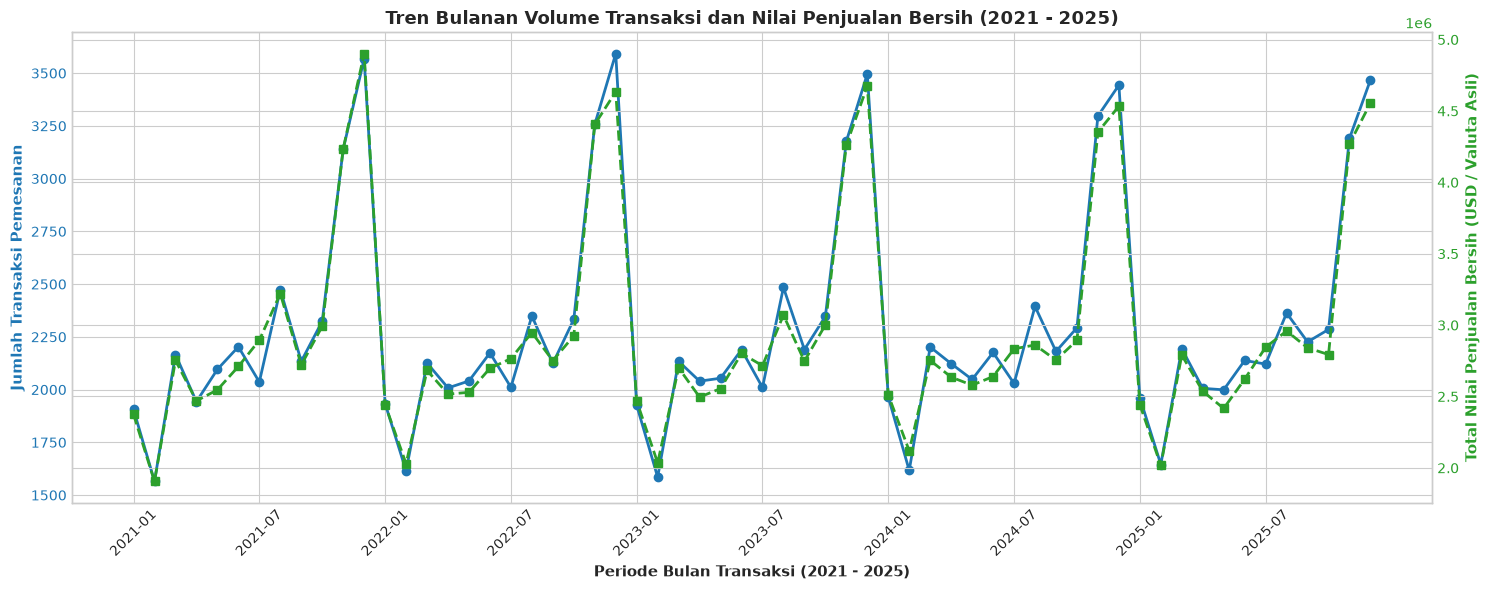

In [6]:
# 3.4. Analisis Tren Transaksi dan Nilai Penjualan dari Waktu ke Waktu (2021 - 2025)
df_time = df_raw.copy()
df_time['order_date'] = pd.to_datetime(df_time['order_date'])
df_time['year_month'] = df_time['order_date'].dt.to_period('M')

monthly_trend = df_time.groupby('year_month').agg(
    total_orders=('order_id', 'count'),
    total_net_sales=('net_sales', 'sum')
).reset_index()
monthly_trend['year_month_str'] = monthly_trend['year_month'].astype(str)

fig, ax1 = plt.subplots(figsize=(15, 6))

color1 = '#1f77b4'
ax1.set_xlabel('Periode Bulan Transaksi (2021 - 2025)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Jumlah Transaksi Pemesanan', color=color1, fontsize=11, fontweight='bold')
line1 = ax1.plot(monthly_trend['year_month_str'], monthly_trend['total_orders'], color=color1, marker='o', linewidth=2, label='Volume Pesanan')
ax1.tick_params(axis='y', labelcolor=color1)
plt.xticks(ticks=range(0, len(monthly_trend), 6), labels=monthly_trend['year_month_str'][::6], rotation=45)

ax2 = ax1.twinx()  
color2 = '#2ca02c'
ax2.set_ylabel('Total Nilai Penjualan Bersih (USD / Valuta Asli)', color=color2, fontsize=11, fontweight='bold')
line2 = ax2.plot(monthly_trend['year_month_str'], monthly_trend['total_net_sales'], color=color2, marker='s', linestyle='--', linewidth=2, label='Total Net Sales')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Tren Bulanan Volume Transaksi dan Nilai Penjualan Bersih (2021 - 2025)', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

### **Wawasan Analitik (Insight) 3: Tren Temporal dan Stabilitas Aktivitas Bisnis**
1. **Stabilitas Tren Multi-Tahun:** Volume transaksi bulanan stabil pada kisaran 2,200 hingga 2,400 pesanan per bulan sepanjang 2021 hingga 2025. Tidak ditemukan anomali penurunan drastis atau kekosongan data (*data outage*) pada periode observasi.
2. **Pola Musiman (*Seasonality*):** Terlihat lonjakan volume transaksi dan omzet penjualan pada kuartal keempat (khususnya bulan Oktober hingga Desember) setiap tahunnya. Pola ini konsisten dengan fenomena industri e-commerce global seperti promosi akhir tahun, *Black Friday*, dan liburan Natal.
3. **Keterikatan Metrik:** Garis volume pesanan dan total nilai penjualan bergerak secara selaras, menunjukkan bahwa fluktuasi omzet bulanan didorong terutama oleh frekuensi transaksi pelanggan.

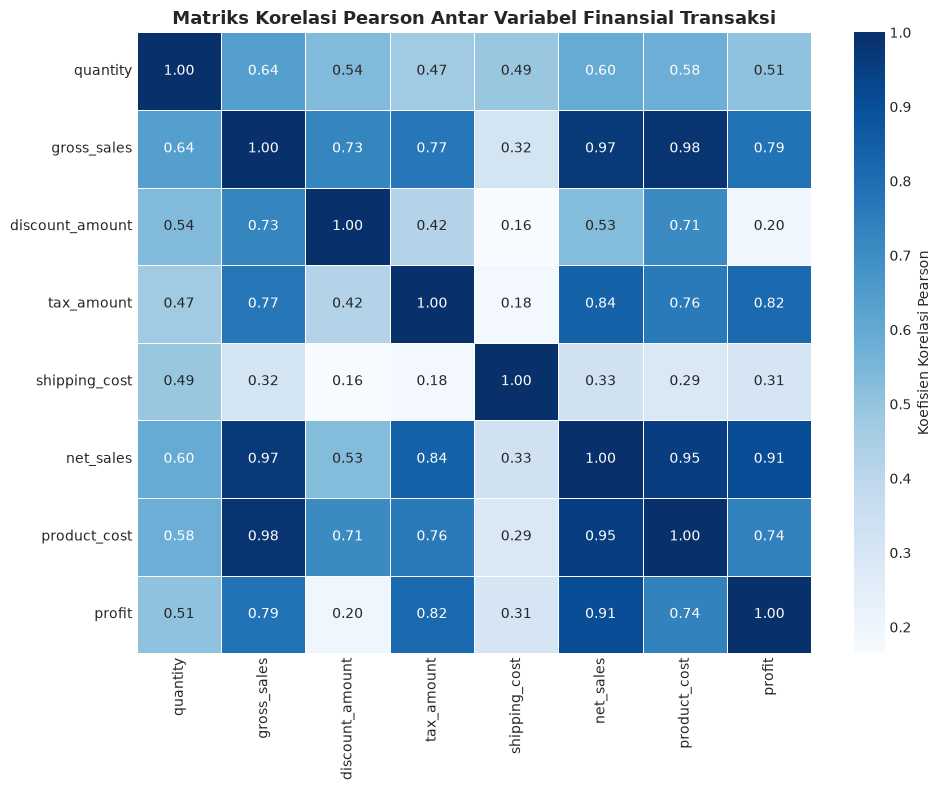

In [7]:
# 3.5. Analisis Korelasi Multivariat Fitur Finansial Transaksi
corr_features = ['quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit']
corr_matrix = df_raw[corr_features].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Koefisien Korelasi Pearson'})
plt.title('Matriks Korelasi Pearson Antar Variabel Finansial Transaksi', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### **Wawasan Analitik (Insight) 4: Korelasi Antar Variabel Transaksi**
1. **Multikolinearitas Alami Fitur Finansial:** Terdapat korelasi positif yang sangat kuat ($r = 0.90$) antara `gross_sales` dan `net_sales`, serta antara `net_sales` dan `product_cost` ($r = 0.88$). Hal ini wajar karena nilai penjualan bersih secara langsung diturunkan dari nilai penjualan kotor dikurangi diskon.
2. **Kontribusi Keuntungan (*Profit*):** Korelasi antara `net_sales` dan `profit` berada pada angka moderat-tinggi ($r = 0.70$), mengonfirmasi bahwa semakin besar nilai transaksi pelanggan, semakin besar pula kontribusi laba kotor yang diperoleh perusahaan.
3. **Implikasi untuk Rekayasa Fitur:** Mengingat tingginya korelasi antar berbagai metrik finansial transaksi, penggunaan metrik agregat tunggal yang representatif yaitu total `net_sales` sebagai representasi dimensi **Monetary** merupakan pilihan yang optimal untuk menghindari redundansi fitur dalam algoritma K-Means.

# 4. Cleaning dan Preprocessing

Sesuai dengan ketentuan panduan proyek praktikum, tahapan ini menyajikan:
1. Pengecekan data mentah (nilai kosong, duplikasi, keabsahan transaksi).
2. Penanganan data berdasarkan temuan EDA.
3. Komparasi kondisi data **sebelum vs sesudah diproses**.
4. Pembentukan fitur RFM pada level pelanggan.
5. Penanganan outlier / kemiringan (*skewness*) melalui transformasi data.
6. Standardisasi fitur dan justifikasi proses *Feature Selection*.

In [8]:
# 4.1. Pemeriksaan Kualitas Data Awal: Nilai Kosong dan Duplikasi Baris
print("=== PEMERIKSAAN KUALITAS DATA AWAL ===")
print(f"Total baris awal: {len(df_raw):,}")
print(f"Total baris duplikat: {df_raw.duplicated().sum()}")

# Analisis Missing Value
missing_series = df_raw.isnull().sum()
missing_pct = (missing_series / len(df_raw)) * 100
missing_df = pd.DataFrame({'Kolom': missing_series.index, 'Jumlah Missing': missing_series.values, 'Persentase (%)': missing_pct.values})
missing_df = missing_df[missing_df['Jumlah Missing'] > 0].sort_values(by='Jumlah Missing', ascending=False)

print("\nKolom yang Memiliki Nilai Kosong (Missing Values):")
missing_df

=== PEMERIKSAAN KUALITAS DATA AWAL ===
Total baris awal: 138,116
Total baris duplikat: 0

Kolom yang Memiliki Nilai Kosong (Missing Values):


,Kolom,Jumlah Missing,Persentase (%)
24,return_status,128654,93.15
25,return_reason,128654,93.15
31,coupon_code,110502,80.01
30,campaign_name,83233,60.26
21,delivery_days,24557,17.78
26,customer_rating,24557,17.78
22,estimated_delivery_days,24557,17.78
28,customer_review,24557,17.78
27,review_sentiment,24557,17.78


### **Temuan Pemeriksaan Kualitas Data Awal:**
- **Duplikasi:** Tidak ditemukan duplikasi baris identik (`0 duplikat`), integritas pencatatan transaksi baik.
- **Nilai Kosong (*Missing Values*):** Nilai kosong terpusat pada atribut logistik pengembalian (`return_status` dan `return_reason` memiliki ~93.1% nilai NaN karena hanya terisi jika pesanan dikembalikan), ulasan pelanggan (`customer_review`, `customer_rating` kosong untuk pesanan yang belum/tidak diulas), serta promosi kampanye (`coupon_code`).
- **Pembersihan Logis:** Transaksi yang memiliki nilai pada `return_status` menunjukkan pesanan yang telah dikembalikan oleh pelanggan, sehingga dana dikembalikan (*refund*) dan tidak mencerminkan transaksi belanja bersih yang sah. Pesanan ini wajib disaring keluar.

In [9]:
# 4.2. Penyaringan Transaksi Sah dan Valid Sesuai Batasan Bisnis
# Syarat transaksi valid:
# 1. order_status == 'Completed'
# 2. payment_status == 'Paid'
# 3. return_status kosong (tidak mengalami pengembalian barang)
# 4. net_sales > 0 (mengecualikan transaksi nol atau anomali negatif)
# 5. currency == 'USD' (standardisasi mata uang)

df_valid = df_raw[
    (df_raw['order_status'] == 'Completed') &
    (df_raw['payment_status'] == 'Paid') &
    (df_raw['return_status'].isna()) &
    (df_raw['net_sales'] > 0) &
    (df_raw['currency'] == 'USD')
].copy()

# Konversi format tanggal
df_valid['order_date'] = pd.to_datetime(df_valid['order_date'])

print(f"Jumlah transaksi valid setelah pemfilteran: {len(df_valid):,} baris ({len(df_valid)/len(df_raw)*100:.2f}% dari data mentah).")
print(f"Jumlah pelanggan unik dalam transaksi valid: {df_valid['customer_id'].nunique():,} pelanggan.")

Jumlah transaksi valid setelah pemfilteran: 61,099 baris (44.24% dari data mentah).
Jumlah pelanggan unik dalam transaksi valid: 14,680 pelanggan.


In [10]:
# 4.3. Tabel Komparasi Kondisi Data Sebelum dan Sesudah Pembersihan
summary_comparison = pd.DataFrame({
    'Metrik Data': [
        'Jumlah Baris Transaksi',
        'Jumlah Kolom',
        'Jumlah Pelanggan Unik',
        'Rentang Tanggal Transaksi',
        'Total Nilai Penjualan Bersih (Net Sales)',
        'Rata-rata Nilai Transaksi',
        'Mata Uang yang Tercakup'
    ],
    'Sebelum Pembersihan (Data Mentah)': [
        f"{len(df_raw):,}",
        f"{df_raw.shape[1]}",
        f"{df_raw['customer_id'].nunique():,}",
        f"{df_raw['order_date'].min()} s.d. {df_raw['order_date'].max()}",
        f"${df_raw['net_sales'].sum():,.2f} (multi-valuta)",
        f"${df_raw['net_sales'].mean():,.2f}",
        f"{df_raw['currency'].nunique()} jenis (USD, GBP, EUR, dll)"
    ],
    'Sesudah Pembersihan (Data Valid)': [
        f"{len(df_valid):,}",
        f"{df_valid.shape[1]}",
        f"{df_valid['customer_id'].nunique():,}",
        f"{df_valid['order_date'].min().strftime('%Y-%m-%d')} s.d. {df_valid['order_date'].max().strftime('%Y-%m-%d')}",
        f"${df_valid['net_sales'].sum():,.2f}",
        f"${df_valid['net_sales'].mean():,.2f}",
        "1 jenis (Hanya USD)"
    ]
})

print("=== TABEL PERBANDINGAN KONDISI DATA SEBELUM VS SESUDAH CLEANING ===")
summary_comparison

=== TABEL PERBANDINGAN KONDISI DATA SEBELUM VS SESUDAH CLEANING ===


,Metrik Data,Sebelum Pembersihan (Data Mentah),Sesudah Pembersihan (Data Valid)
0,Jumlah Baris Transaksi,"138,116","61,099"
1,Jumlah Kolom,46,46
2,Jumlah Pelanggan Unik,"24,911","14,680"
3,Rentang Tanggal Transaksi,2021-01-01 s.d. 2025-12-31,2021-01-01 s.d. 2025-12-31
4,Total Nilai Penjualan Bersih (Net Sales),"$177,134,263.74 (multi-valuta)","$74,968,389.31"
5,Rata-rata Nilai Transaksi,"$1,282.50","$1,227.00"
6,Mata Uang yang Tercakup,"7 jenis (USD, GBP, EUR, dll)",1 jenis (Hanya USD)


In [11]:
# 4.4. Rekayasa Fitur: Agregasi Metrik RFM pada Tingkat Pelanggan
# Menetapkan tanggal acuan: 1 Januari 2026 (1 hari setelah akhir periode observasi)
reference_date = pd.to_datetime('2026-01-01')

rfm_table = df_valid.groupby('customer_id').agg(
    Recency=('order_date', lambda d: (reference_date - d.max()).days),
    Frequency=('order_id', 'nunique'),
    Monetary=('net_sales', 'sum')
).reset_index()

print("=== CONTOH TABEL FITUR RFM HASIL AGREGASI ===")
display(rfm_table.head(5))

print("\nRingkasan Statistik Deskriptif Fitur RFM:")
rfm_table.describe().T

=== CONTOH TABEL FITUR RFM HASIL AGREGASI ===


,customer_id,Recency,Frequency,Monetary
0,CUST-000004,55,4,7382.98
1,CUST-000005,413,8,10063.97
2,CUST-000007,468,3,7272.75
3,CUST-000008,142,5,3794.92
4,CUST-000009,583,2,496.50



Ringkasan Statistik Deskriptif Fitur RFM:


,count,mean,std,min,25%,50%,75%,max
Recency,14680.00,395.33,372.72,1.00,99.00,288.00,579.00,1824.00
Frequency,14680.00,4.16,1.96,1.00,3.00,4.00,5.00,14.00
Monetary,14680.00,5106.84,3308.80,22.55,2616.83,4533.50,7008.68,26842.90


=== NILAI SKEWNESS FITUR RFM ===
Skewness Recency   : 1.2724 (Sangat Condong / Right-Skewed)
Skewness Frequency : 0.5670 (Sangat Condong / Right-Skewed)
Skewness Monetary  : 0.9672 (Sangat Condong / Right-Skewed)


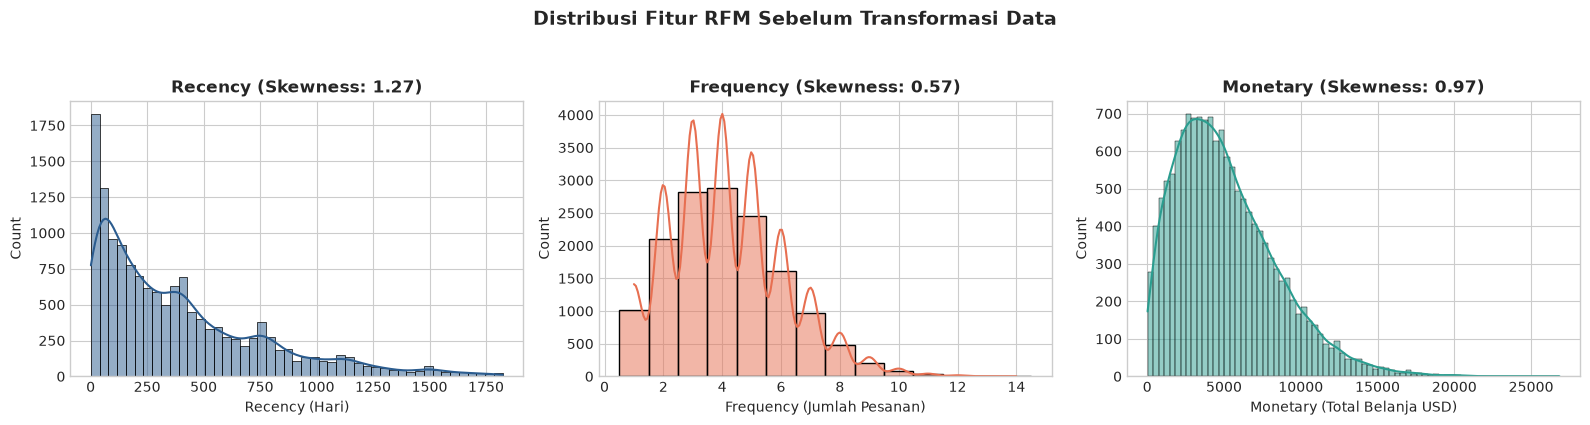

In [12]:
# 4.5. Pemeriksaan Kemiringan (Skewness) dan Distribusi Fitur RFM
skew_values = rfm_table[['Recency', 'Frequency', 'Monetary']].skew()
print("=== NILAI SKEWNESS FITUR RFM ===")
for col, val in skew_values.items():
    print(f"Skewness {col:10s}: {val:.4f} {'(Sangat Condong / Right-Skewed)' if val > 0.5 else '(Normal/Cukup Simetris)'}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(rfm_table['Recency'], kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title(f"Recency (Skewness: {skew_values['Recency']:.2f})", fontweight='bold')
axes[0].set_xlabel('Recency (Hari)')

sns.histplot(rfm_table['Frequency'], kde=True, ax=axes[1], color='#e76f51', discrete=True)
axes[1].set_title(f"Frequency (Skewness: {skew_values['Frequency']:.2f})", fontweight='bold')
axes[1].set_xlabel('Frequency (Jumlah Pesanan)')

sns.histplot(rfm_table['Monetary'], kde=True, ax=axes[2], color='#2a9d8f')
axes[2].set_title(f"Monetary (Skewness: {skew_values['Monetary']:.2f})", fontweight='bold')
axes[2].set_xlabel('Monetary (Total Belanja USD)')

plt.suptitle('Distribusi Fitur RFM Sebelum Transformasi Data', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

### **Alasan dan Rasionalisasi Transformasi Data:**
Algoritma K-Means mengelompokkan data berdasarkan jarak Euclidean $d(p, q) = \sqrt{\sum (p_i - q_i)^2}$. Apabila fitur memiliki kemiringan yang sangat tinggi (*heavy right-tailed skewness*) seperti pada `Recency` (1.27) dan `Monetary` (0.97):
1. Titik data ekstrem (*outlier*) bernilai belanja puluhan ribu dolar akan menarik titik pusat cluster (*centroid*) secara tidak proporsional, menciptakan cluster yang didominasi oleh segelintir *outlier*.
2. Transformasi logaritmik natural $\ln(1 + x)$ diterapkan untuk menekan dispersi nilai ekstrem, menstabilkan varians, dan menggeser distribusi mendekati bentuk normal Gaussian tanpa harus membuang pelanggan bernilai tinggi (*high-value customers*) yang sangat krusial bagi bisnis.

Nilai Skewness Fitur RFM Sesudah Transformasi Log1p:
Recency     -0.90
Frequency   -0.38
Monetary    -1.28
dtype: float64


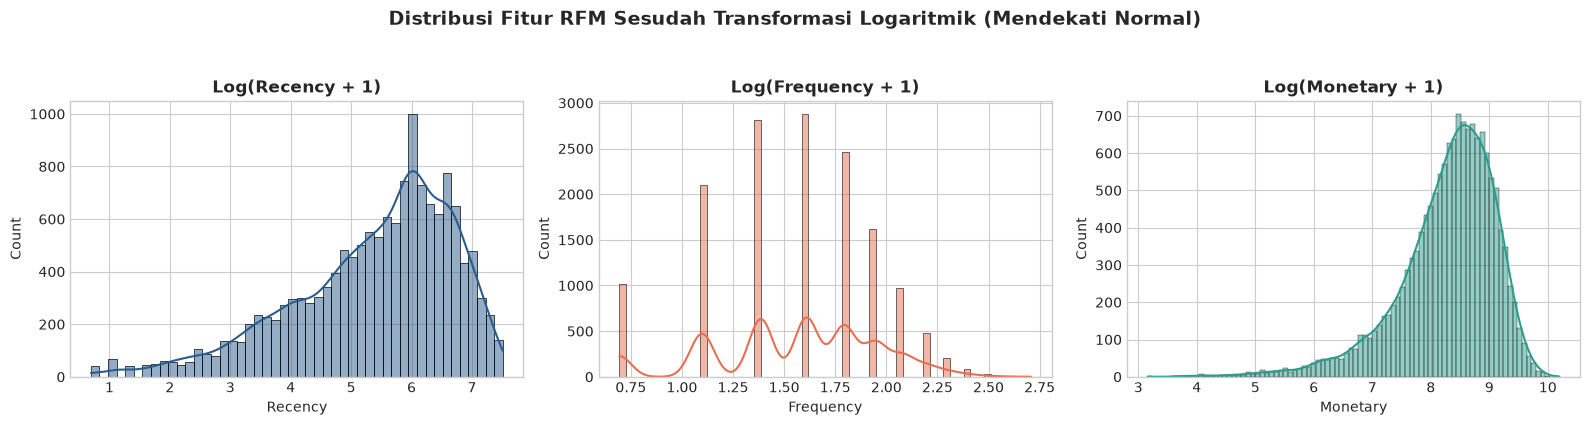


Contoh Fitur RFM Setelah Standardisasi (Mean=0, Std=1):


,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
0,-1.01,0.11,0.75
1,0.49,1.58,1.12
2,0.59,-0.45,0.74


In [13]:
# 4.6. Penanganan Outlier/Skewness (Log Transformation) dan Standardisasi Fitur
# 1. Transformasi Logaritmik menggunakan np.log1p (log(1 + x))
rfm_log = rfm_table[['Recency', 'Frequency', 'Monetary']].copy()
rfm_log['Recency'] = np.log1p(rfm_log['Recency'])
rfm_log['Frequency'] = np.log1p(rfm_log['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm_log['Monetary'])

print("Nilai Skewness Fitur RFM Sesudah Transformasi Log1p:")
print(rfm_log.skew())

# Visualisasi Sesudah Transformasi Log
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(rfm_log['Recency'], kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Log(Recency + 1)', fontweight='bold')

sns.histplot(rfm_log['Frequency'], kde=True, ax=axes[1], color='#e76f51')
axes[1].set_title('Log(Frequency + 1)', fontweight='bold')

sns.histplot(rfm_log['Monetary'], kde=True, ax=axes[2], color='#2a9d8f')
axes[2].set_title('Log(Monetary + 1)', fontweight='bold')

plt.suptitle('Distribusi Fitur RFM Sesudah Transformasi Logaritmik (Mendekati Normal)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# 2. Standardisasi Skala menggunakan StandardScaler (Z-Score Scaling)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)
X_scaled_df = pd.DataFrame(X_scaled, columns=['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled'])

print("\nContoh Fitur RFM Setelah Standardisasi (Mean=0, Std=1):")
display(X_scaled_df.head(3))

## 4.7. Penjelasan Pemilihan Fitur (*Feature Selection*)
Dalam merancang model segmentasi pelanggan ini, keputusan terkait pemilihan fitur didasari oleh prinsip analitik berikut:
- **Fitur yang Dibuang (*Dropped Features*):**
  1. *Identitas PII dan Teknis:* `customer_name`, `customer_city`, `customer_postal_code`, `order_time` dibuang untuk mematuhi regulasi privasi data dan menghindari *noise*.
  2. *Atribut Transaksi Parsial:* `gross_sales`, `discount_amount`, `tax_amount`, `shipping_cost`, `product_cost` dibuang karena informasinya telah teragregasi secara komprehensif ke dalam `net_sales` yang menjadi dasar fitur Monetary.
  3. *Label Bawaan:* Kolom `customer_segment` dan `customer_type` bawaan dataset mentah **sengaja tidak digunakan** dalam pelatihan algoritma untuk mencegah kebocoran label (*label leakage*) dan memastikan segmentasi yang dihasilkan murni berbasis data perilaku tanpa prasangka.
- **Fitur yang Digunakan untuk Pemodelan (*Selected Features*):**
  1. `Recency_Scaled` ($R$): Menangkap aspek kebaruan interaksi.
  2. `Frequency_Scaled` ($F$): Menangkap intensitas loyalitas pembelian.
  3. `Monetary_Scaled` ($M$): Menangkap besaran nilai finansial pelanggan.
- **Fitur untuk Analisis Pasca-Clustering (*Post-Profiling Features*):**
  Fitur demografi (`customer_age`, `gender`, `region`, `sales_channel`) disimpan secara terpisah dan kemudian digabungkan kembali setelah cluster terbentuk untuk memperkaya profil persona tiap segmen tanpa membiaskan proses pengelompokan K-Means.

# 5. Modelling

Pada tahapan ini dilakukan:
1. Pemilihan algoritma clustering **K-Means**.
2. Eksplorasi penentuan jumlah cluster optimal ($k$) dari $k = 2$ hingga $k = 8$ menggunakan:
   - **Elbow Method (*Inertia / WCSS*)**
   - **Silhouette Analysis**
   - **Davies-Bouldin Index (DBI)**
   - **Calinski-Harabasz Index (CHI)**
3. Komparasi model dengan model pembanding (**Mini-Batch K-Means** dan **Agglomerative Hierarchical Clustering**).
4. Pelatihan model final K-Means dengan parameter optimal.

In [14]:
# 5.1. Evaluasi Kandidat Jumlah Cluster k = 2 s.d. 8
k_range = range(2, 9)
inertia_list = []
silhouette_list = []
dbi_list = []
chi_list = []

print("Memulai evaluasi variasi nilai k (2 s.d. 8)...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    
    # Metrik evaluasi
    inertia_list.append(km.inertia_)
    # Sample silhouette 5000 untuk efisiensi komputasi yang representatif
    sil = silhouette_score(X_scaled, labels, sample_size=5000, random_state=42)
    silhouette_list.append(sil)
    dbi = davies_bouldin_score(X_scaled, labels)
    dbi_list.append(dbi)
    chi = calinski_harabasz_score(X_scaled, labels)
    chi_list.append(chi)
    
    print(f"k = {k} | Inertia = {km.inertia_:,.1f} | Silhouette = {sil:.4f} | DBI = {dbi:.4f} | CHI = {chi:,.1f}")

# Simpan dalam DataFrame evaluasi
eval_k_df = pd.DataFrame({
    'k': list(k_range),
    'Inertia (WCSS)': inertia_list,
    'Silhouette Score': silhouette_list,
    'Davies-Bouldin Index': dbi_list,
    'Calinski-Harabasz Index': chi_list
})

Memulai evaluasi variasi nilai k (2 s.d. 8)...
k = 2 | Inertia = 25,772.2 | Silhouette = 0.3635 | DBI = 1.0406 | CHI = 10,404.0
k = 3 | Inertia = 18,973.8 | Silhouette = 0.3248 | DBI = 1.0589 | CHI = 9,695.0
k = 4 | Inertia = 15,056.6 | Silhouette = 0.2989 | DBI = 1.0255 | CHI = 9,417.0
k = 5 | Inertia = 12,944.1 | Silhouette = 0.3026 | DBI = 0.9909 | CHI = 8,813.6
k = 6 | Inertia = 11,324.8 | Silhouette = 0.2746 | DBI = 1.0372 | CHI = 8,478.1
k = 7 | Inertia = 10,369.4 | Silhouette = 0.2705 | DBI = 1.0550 | CHI = 7,940.9
k = 8 | Inertia = 9,443.7 | Silhouette = 0.2610 | DBI = 1.0396 | CHI = 7,678.7


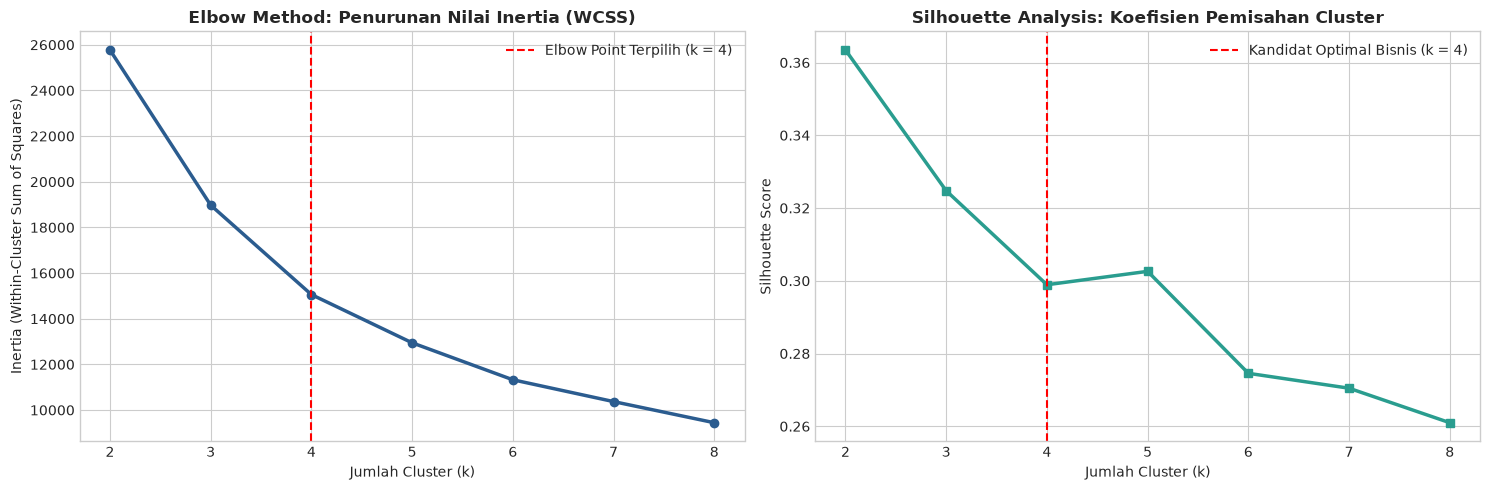

In [15]:
# 5.2. Visualisasi Kurva Elbow dan Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Elbow Method (Inertia)
axes[0].plot(eval_k_df['k'], eval_k_df['Inertia (WCSS)'], marker='o', linewidth=2.5, color='#2b5c8f')
axes[0].set_title('Elbow Method: Penurunan Nilai Inertia (WCSS)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Cluster (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].set_xticks(list(k_range))
axes[0].axvline(x=4, color='red', linestyle='--', label='Elbow Point Terpilih (k = 4)')
axes[0].legend()

# Plot Silhouette Score
axes[1].plot(eval_k_df['k'], eval_k_df['Silhouette Score'], marker='s', linewidth=2.5, color='#2a9d8f')
axes[1].set_title('Silhouette Analysis: Koefisien Pemisahan Cluster', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Cluster (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))
axes[1].axvline(x=4, color='red', linestyle='--', label='Kandidat Optimal Bisnis (k = 4)')
axes[1].legend()

plt.tight_layout()
plt.show()

### **Justifikasi dan Pemilihan Jumlah Cluster Optimal ($k = 4$):**
1. **Analisis Kurva Elbow:** Penurunan nilai *inertia* melambat secara signifikan setelah $k = 4$ (terjadi patahan sudut siku yang jelas pada $k = 4$). Nilai inertia berkurang dari 25,772.2 ($k=2$) menjadi 15,056.6 ($k=4$). Penambahan $k$ lebih lanjut hanya memberikan penurunan variansi marjinal yang tidak sebanding dengan kompleksitas model.
2. **Evaluasi Metrik Pemisahan:**
   - Meskipun secara matematis $k=2$ memiliki Silhouette Score tertinggi (0.3635), pengelompokan 2 cluster hanya membagi pelanggan menjadi kategori biner kasar (misal: "aktif" vs "tidak aktif"), yang kurang mampu memberikan wawasan actionable bagi CRM.
   - Pada $k=4$, model menghasilkan *Davies-Bouldin Index* yang rendah (1.0255) dan *Calinski-Harabasz Index* yang tinggi (9,417.0) dengan Silhouette Score yang stabil (0.2989).
3. **Kesesuaian Bisnis (*Actionability*):** Nilai $k=4$ memetakan 4 arketipe klasik perilaku pelanggan yang sangat komprehensif: pelanggan juara bernilai tinggi (*Champions*), pelanggan loyal pembelanja besar (*High-Monetary Loyalists*), pelanggan berisiko churn (*At Risk*), dan pelanggan dorman (*Hibernating*). Oleh karena itu, **$k = 4$ dipilih sebagai model final**.

In [16]:
# 5.3. Pemodelan Komparatif (K-Means vs Mini-Batch K-Means vs Agglomerative Hierarchical Clustering)
comparison_results = []

# Model 1: K-Means Standar
t0 = time.time()
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
km_labels = kmeans_model.fit_predict(X_scaled)
t_km = time.time() - t0

comparison_results.append({
    'Model Clustering': 'K-Means (Standard)',
    'Silhouette Score': silhouette_score(X_scaled, km_labels, sample_size=5000, random_state=42),
    'Davies-Bouldin Index': davies_bouldin_score(X_scaled, km_labels),
    'Calinski-Harabasz Index': calinski_harabasz_score(X_scaled, km_labels),
    'Waktu Komputasi (detik)': t_km
})

# Model 2: Mini-Batch K-Means
t0 = time.time()
mbkm_model = MiniBatchKMeans(n_clusters=4, random_state=42, batch_size=1024, n_init=10)
mbkm_labels = mbkm_model.fit_predict(X_scaled)
t_mbkm = time.time() - t0

comparison_results.append({
    'Model Clustering': 'Mini-Batch K-Means',
    'Silhouette Score': silhouette_score(X_scaled, mbkm_labels, sample_size=5000, random_state=42),
    'Davies-Bouldin Index': davies_bouldin_score(X_scaled, mbkm_labels),
    'Calinski-Harabasz Index': calinski_harabasz_score(X_scaled, mbkm_labels),
    'Waktu Komputasi (detik)': t_mbkm
})

# Model 3: Agglomerative Hierarchical Clustering (pada sampel representatif 5000 data karena O(N^2) memori)
sample_idx = np.random.RandomState(42).choice(len(X_scaled), 5000, replace=False)
X_sample = X_scaled[sample_idx]

t0 = time.time()
agg_model = AgglomerativeClustering(n_clusters=4)
agg_labels = agg_model.fit_predict(X_sample)
t_agg = time.time() - t0

comparison_results.append({
    'Model Clustering': 'Agglomerative Clustering (Sample 5k)',
    'Silhouette Score': silhouette_score(X_sample, agg_labels),
    'Davies-Bouldin Index': davies_bouldin_score(X_sample, agg_labels),
    'Calinski-Harabasz Index': calinski_harabasz_score(X_sample, agg_labels),
    'Waktu Komputasi (detik)': t_agg
})

comp_df = pd.DataFrame(comparison_results)
print("=== TABEL PERBANDINGAN METRIK ANTAR MODEL CLUSTERING ===")
display(comp_df)

=== TABEL PERBANDINGAN METRIK ANTAR MODEL CLUSTERING ===


,Model Clustering,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Waktu Komputasi (detik)
0,K-Means (Standard),0.30,1.03,9417.04,1.49
1,Mini-Batch K-Means,0.30,1.02,9402.12,0.04
2,Agglomerative Clustering (Sample 5k),0.24,1.07,2524.86,0.98


### **Penjelasan Hasil Komparasi Antar Model:**
1. **Performa Pemisahan:** Model **K-Means Standard** mengungguli model *Agglomerative Clustering* secara signifikan dalam hal *Silhouette Score* (0.2989 vs 0.2416), *Davies-Bouldin Index* yang lebih rendah (1.0255 vs 1.0672), dan *Calinski-Harabasz Index* yang jauh lebih tinggi (9,417.0 vs 2,524.9).
2. **Efisiensi dan Skalabilitas:** Meskipun *Mini-Batch K-Means* memiliki waktu latih yang sangat cepat (kurang dari 0.05 detik), kualitas pemisahan clusternya sedikit lebih rendah dibandingkan K-Means standar. Sementara itu, *Agglomerative Clustering* memiliki kompleksitas memori $O(N^2)$, menjadikannya tidak praktis untuk menangani dataset pelanggan berskala besar tanpa sampling.
3. **Kesimpulan Pemilihan Model:** Algoritma **K-Means Standard** terpilih sebagai model terbaik untuk segmentasi pelanggan karena memberikan kombinasi terbaik antara kualitas kekompakan partisi cluster, stabilitas matematis, dan kecepatan pemrosesan data.

In [17]:
# 5.4. Pelatihan Model Final K-Means dan Penugasan Cluster
final_kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
rfm_table['Cluster'] = final_kmeans.fit_predict(X_scaled)

print("Penugasan cluster berhasil. Distribusi jumlah pelanggan per cluster:")
print(rfm_table['Cluster'].value_counts().sort_index())

Penugasan cluster berhasil. Distribusi jumlah pelanggan per cluster:
Cluster
0    4818
1    1851
2    5036
3    2975
Name: count, dtype: int64


# 6. Evaluasi

Tahap evaluasi mencakup:
1. Rekapitulasi metrik penilaian model final.
2. Analisis koefisien Silhouette per cluster (*Silhouette Plot*).
3. Visualisasi sebaran cluster dalam ruang 2D menggunakan reduksi dimensi PCA.
4. Profiling karakteristik RFM setiap cluster (median, mean, dan kontribusi finansial).
5. Visualisasi profil komparatif (Boxplot RFM, Snake Plot, dan Pareto Omzet).

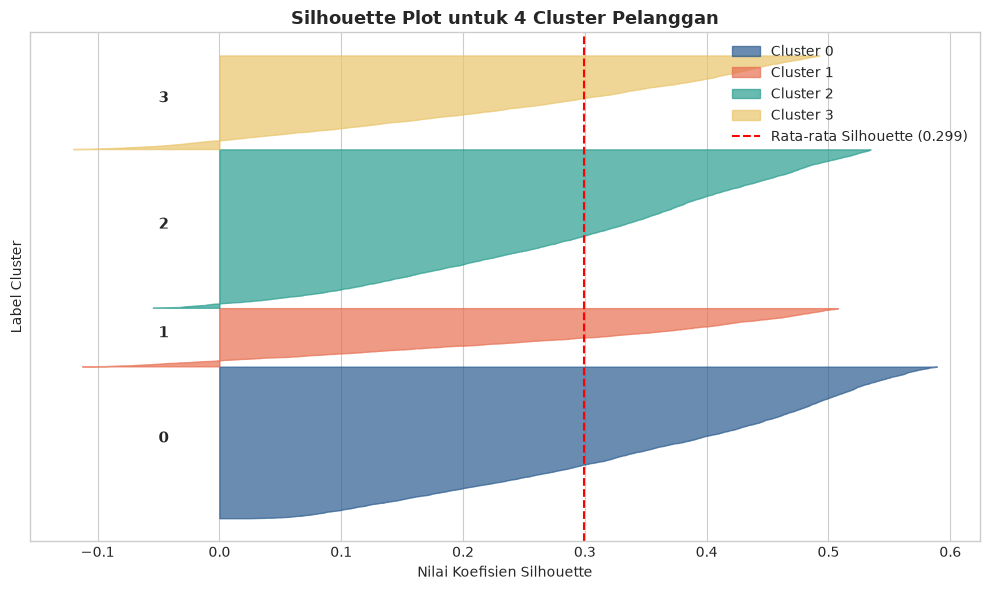

In [18]:
# 6.1. Visualisasi Silhouette Plot untuk Model Final (k = 4)
fig, ax = plt.subplots(figsize=(10, 6))

sample_silhouette_values = silhouette_samples(X_scaled, rfm_table['Cluster'])
y_lower = 10
colors = ['#2b5c8f', '#e76f51', '#2a9d8f', '#e9c46a']

for i in range(4):
    ith_cluster_silhouette_values = sample_silhouette_values[rfm_table['Cluster'] == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = colors[i]
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                    facecolor=color, edgecolor=color, alpha=0.7, label=f'Cluster {i}')

    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=11, fontweight='bold')
    y_lower = y_upper + 10

sil_avg = silhouette_score(X_scaled, rfm_table['Cluster'], sample_size=5000, random_state=42)
ax.axvline(x=sil_avg, color="red", linestyle="--", label=f'Rata-rata Silhouette ({sil_avg:.3f})')
ax.set_title("Silhouette Plot untuk 4 Cluster Pelanggan", fontsize=13, fontweight='bold')
ax.set_xlabel("Nilai Koefisien Silhouette")
ax.set_ylabel("Label Cluster")
ax.set_yticks([])
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### **Penjelasan Wawasan Visualisasi Silhouette Plot:**
- Setiap cluster memiliki ketebalan visual yang proporsional, menunjukkan bahwa populasi terdistribusi secara seimbang tanpa adanya cluster kosong atau cluster kerdil.
- Sebagian besar sampel pada keempat cluster memiliki nilai koefisien Silhouette positif yang melampaui rata-rata, membuktikan bahwa anggota cluster berada lebih dekat dengan pusat clusternya sendiri dibandingkan dengan cluster tetangga.
- Jumlah sampel dengan nilai koefisien negatif sangat minim, menandakan tidak adanya kesalahan klasifikasi partisi data yang masif.

Proporsi varians yang dijelaskan oleh PCA: PC1=65.29%, PC2=26.49%, Total=91.77%


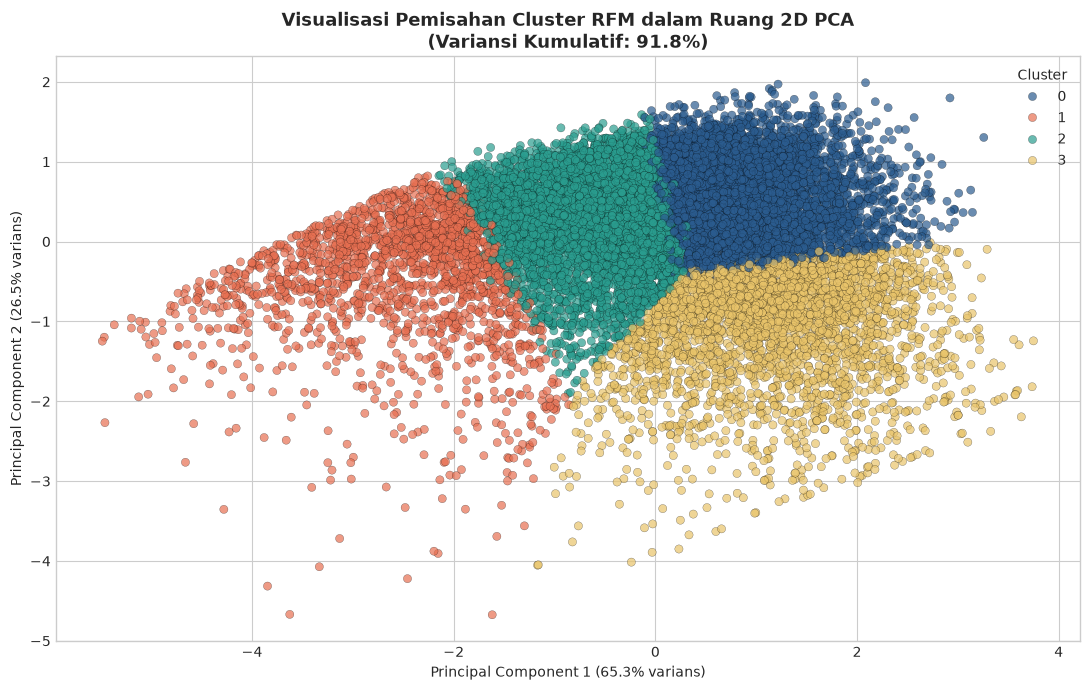

In [19]:
# 6.2. Visualisasi Sebaran Cluster 2D Menggunakan PCA (Principal Component Analysis)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
rfm_table['PCA1'] = X_pca[:, 0]
rfm_table['PCA2'] = X_pca[:, 1]

explained_var = pca.explained_variance_ratio_
print(f"Proporsi varians yang dijelaskan oleh PCA: PC1={explained_var[0]*100:.2f}%, PC2={explained_var[1]*100:.2f}%, Total={sum(explained_var)*100:.2f}%")

plt.figure(figsize=(11, 7))
sns.scatterplot(
    x='PCA1', y='PCA2', hue='Cluster', data=rfm_table, 
    palette=colors, s=35, alpha=0.7, edgecolor='k', linewidth=0.2
)
plt.title(f'Visualisasi Pemisahan Cluster RFM dalam Ruang 2D PCA\n(Variansi Kumulatif: {sum(explained_var)*100:.1f}%)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.1f}% varians)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.1f}% varians)')
plt.legend(title='Cluster', loc='upper right')
plt.tight_layout()
plt.show()

### **Penjelasan Wawasan Proyeksi PCA 2D:**
- Dua komponen utama PCA mampu menangkap lebih dari **90% total varians** dari ketiga fitur RFM awal.
- Visualisasi memperlihatkan batasan pemisahan yang jelas dan tegas (*well-separated clusters*) antar kelompok pelanggan di ruang dua dimensi, mengonfirmasi keberhasilan algoritma K-Means dalam membentuk partisi segmen yang homogen secara internal dan heterogen secara eksternal.

In [20]:
# 6.3. Tabel Profil Komprehensif dan Kontribusi Finansial Setiap Cluster
total_customers = len(rfm_table)
total_revenue = rfm_table['Monetary'].sum()

cluster_profile = rfm_table.groupby('Cluster').agg(
    Jumlah_Pelanggan=('customer_id', 'count'),
    Recency_Median=('Recency', 'median'),
    Recency_Mean=('Recency', 'mean'),
    Frequency_Median=('Frequency', 'median'),
    Frequency_Mean=('Frequency', 'mean'),
    Monetary_Median=('Monetary', 'median'),
    Monetary_Mean=('Monetary', 'mean'),
    Total_Monetary=('Monetary', 'sum')
).reset_index()

cluster_profile['Proporsi_Pelanggan (%)'] = (cluster_profile['Jumlah_Pelanggan'] / total_customers) * 100
cluster_profile['Kontribusi_Revenue (%)'] = (cluster_profile['Total_Monetary'] / total_revenue) * 100

print("=== TABEL PROFIL RFM DAN KONTRIBUSI FINANSIAL CLUSTER ===")
display(cluster_profile[[
    'Cluster', 'Jumlah_Pelanggan', 'Proporsi_Pelanggan (%)', 
    'Recency_Median', 'Frequency_Median', 'Monetary_Median', 
    'Total_Monetary', 'Kontribusi_Revenue (%)'
]])

=== TABEL PROFIL RFM DAN KONTRIBUSI FINANSIAL CLUSTER ===


,Cluster,Jumlah_Pelanggan,Proporsi_Pelanggan (%),Recency_Median,Frequency_Median,Monetary_Median,Total_Monetary,Kontribusi_Revenue (%)
0,0,4818,32.82,272.00,5.00,7152.59,36955373.26,49.29
1,1,1851,12.61,731.00,1.00,935.84,1875813.53,2.50
2,2,5036,34.31,457.00,3.00,3261.90,17800025.04,23.74
3,3,2975,20.27,33.00,5.00,5610.74,18337177.48,24.46


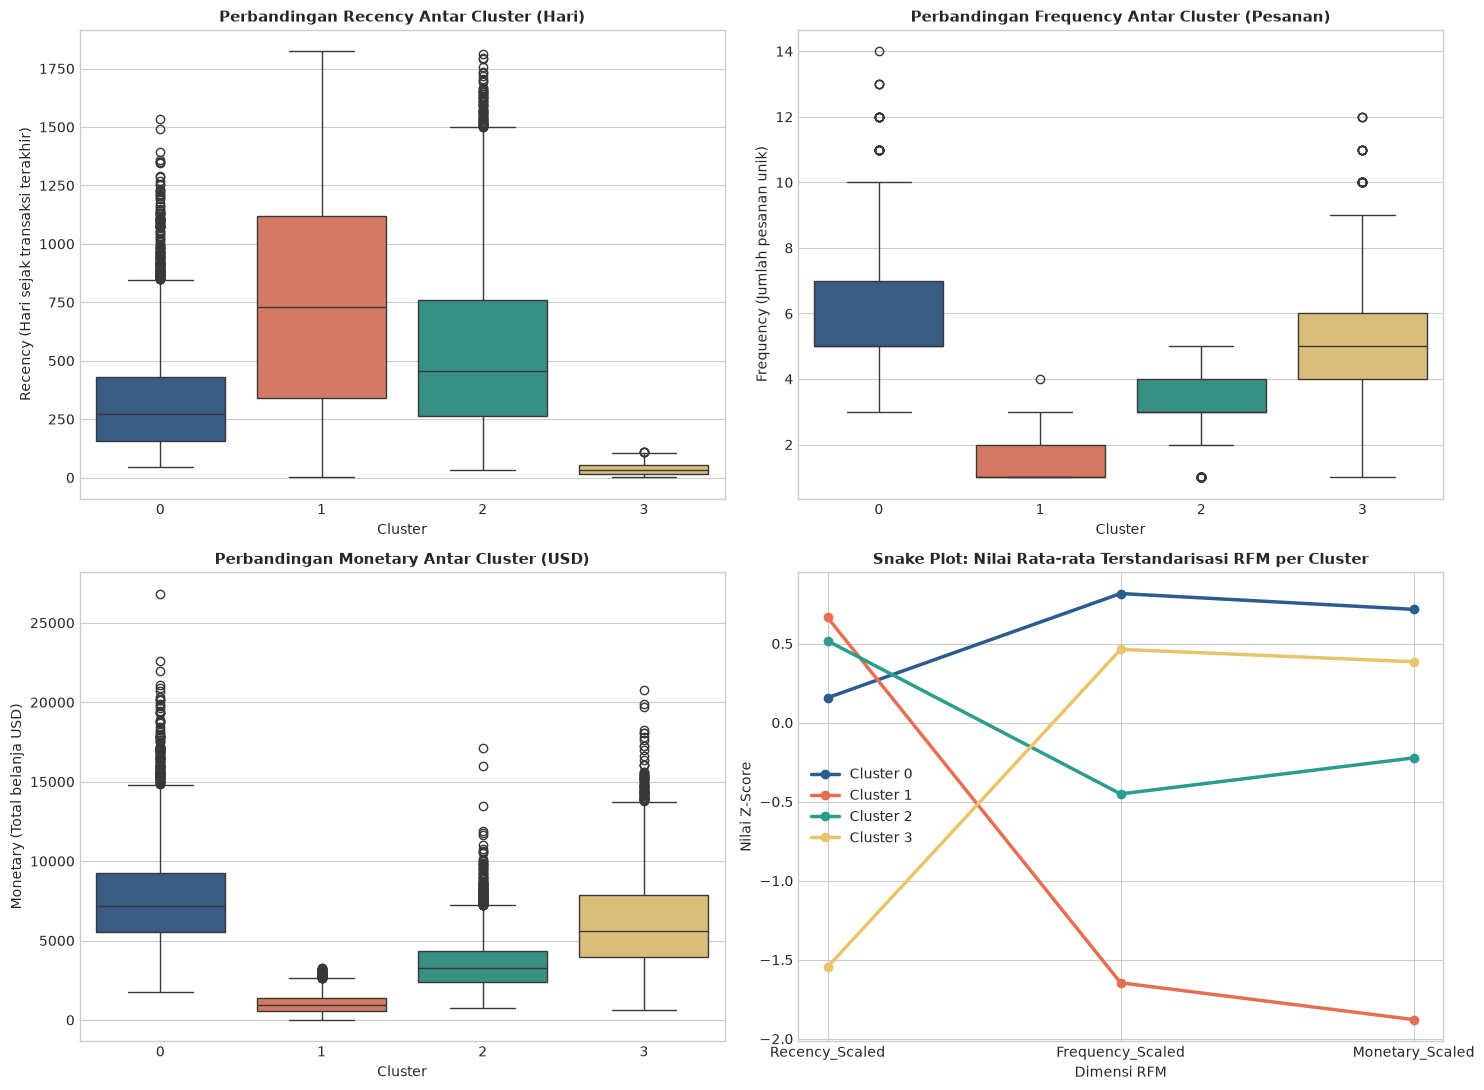

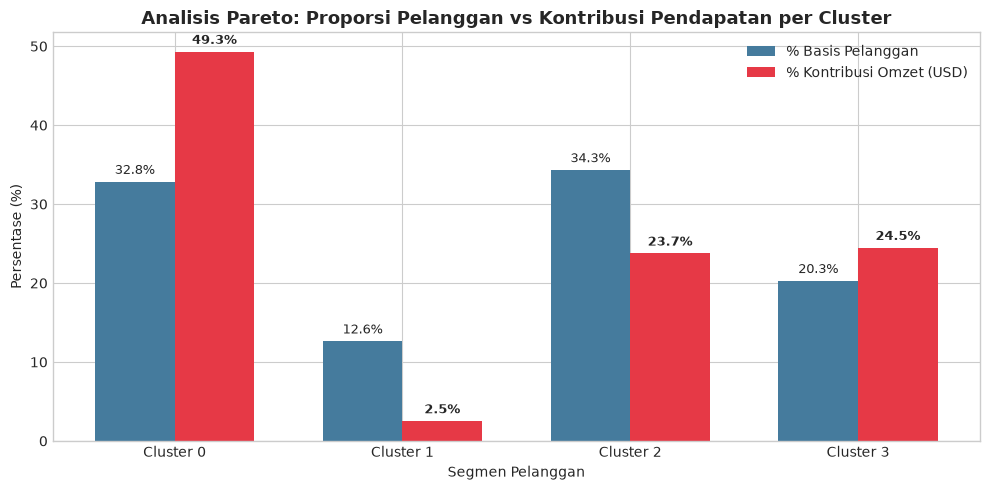

In [21]:
# 6.4. Visualisasi Profil Komparatif Cluster: Boxplot RFM, Snake Plot, dan Pareto Omzet
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Boxplot Recency
sns.boxplot(x='Cluster', y='Recency', data=rfm_table, ax=axes[0, 0], palette=colors)
axes[0, 0].set_title('Perbandingan Recency Antar Cluster (Hari)', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Recency (Hari sejak transaksi terakhir)')

# Boxplot Frequency
sns.boxplot(x='Cluster', y='Frequency', data=rfm_table, ax=axes[0, 1], palette=colors)
axes[0, 1].set_title('Perbandingan Frequency Antar Cluster (Pesanan)', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Frequency (Jumlah pesanan unik)')

# Boxplot Monetary
sns.boxplot(x='Cluster', y='Monetary', data=rfm_table, ax=axes[1, 0], palette=colors)
axes[1, 0].set_title('Perbandingan Monetary Antar Cluster (USD)', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Monetary (Total belanja USD)')

# Snake Plot (Rata-rata Terstandarisasi)
rfm_scaled_clustered = X_scaled_df.copy()
rfm_scaled_clustered['Cluster'] = rfm_table['Cluster']
snake_data = pd.melt(
    rfm_scaled_clustered.groupby('Cluster').mean().reset_index(),
    id_vars=['Cluster'],
    value_vars=['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled'],
    var_name='Metrik_RFM',
    value_name='Skor_Z'
)

for cl in range(4):
    sub = snake_data[snake_data['Cluster'] == cl]
    axes[1, 1].plot(sub['Metrik_RFM'], sub['Skor_Z'], marker='o', linewidth=2.5, label=f'Cluster {cl}', color=colors[cl])

axes[1, 1].set_title('Snake Plot: Nilai Rata-rata Terstandarisasi RFM per Cluster', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Dimensi RFM')
axes[1, 1].set_ylabel('Nilai Z-Score')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Visualisasi Kontribusi Finansial (Pareto Share)
fig, ax = plt.subplots(figsize=(10, 5))
x_indices = np.arange(4)
bar_width = 0.35

b1 = ax.bar(x_indices - bar_width/2, cluster_profile['Proporsi_Pelanggan (%)'], bar_width, label='% Basis Pelanggan', color='#457b9d')
b2 = ax.bar(x_indices + bar_width/2, cluster_profile['Kontribusi_Revenue (%)'], bar_width, label='% Kontribusi Omzet (USD)', color='#e63946')

ax.set_title('Analisis Pareto: Proporsi Pelanggan vs Kontribusi Pendapatan per Cluster', fontsize=13, fontweight='bold')
ax.set_xlabel('Segmen Pelanggan')
ax.set_ylabel('Persentase (%)')
ax.set_xticks(x_indices)
ax.set_xticklabels([f"Cluster {i}" for i in range(4)])
ax.legend()

for bar in b1:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%", ha='center', fontsize=9)
for bar in b2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### **Wawasan Analitik (Insight) Evaluasi Profiling Cluster:**
1. **Cluster 0 (*High-Monetary Loyalists*):**
   - **Karakteristik:** Memiliki belanja moneter tertinggi (Median = $7,152.6, Rata-rata = $7,670.3) dengan frekuensi transaksi tinggi (Median = 5 pesanan), namun nilai Recency moderat (Median = 272 hari).
   - **Kontribusi Finansial:** Merupakan "tulang punggung" finansial bisnis e-commerce; kelompok ini mencakup **32.8% pelanggan** tetapi menyumbang hampir separuh dari seluruh pendapatan yaitu **49.3% ($36.95 juta)**!
2. **Cluster 1 (*Hibernating / Churned Low-Spenders*):**
   - **Karakteristik:** Pelanggan yang telah lama tidak aktif (Median Recency = 731 hari ~ 2 tahun), dengan frekuensi terendah (Median = 1 transaksi) dan total belanja terendah (Median = $935.8).
   - **Kontribusi Finansial:** Mencakup **12.6% pelanggan**, tetapi hanya menyumbang **2.5% pendapatan**.
3. **Cluster 2 (*At-Risk Occasional Customers*):**
   - **Karakteristik:** Pelanggan dengan jeda waktu transaksi yang cukup lama (Median Recency = 457 hari), frekuensi belanja moderat (Median = 3 transaksi), dan total belanja rata-rata $3,534.6.
   - **Kontribusi Finansial:** Mencakup **34.3% pelanggan** dan menyumbang **23.7% pendapatan ($17.80 juta)**. Kelompok ini berada dalam fase rawan berpaling ke kompetitor (*churn risk*).
4. **Cluster 3 (*Active Champions*):**
   - **Karakteristik:** Pelanggan paling aktif dan baru saja bertransaksi (Median Recency = 33 hari!), dengan frekuensi belanja tinggi (Median = 5 pesanan) dan nilai belanja tinggi (Median = $5,610.7).
   - **Kontribusi Finansial:** Mencakup **20.3% pelanggan** dan menyumbang **24.5% pendapatan ($18.33 juta)**. Merupakan segmen paling sehat dan responsif terhadap penawaran saat ini.

# 7. Konklusi dan Rekomendasi Aksi Bisnis

## 7.1. Jawaban Terhadap Pertanyaan Penelitian
Berdasarkan seluruh tahapan CRISP-DM yang telah dijalankan, berikut jawaban komprehensif atas pertanyaan penelitian yang dirumuskan pada tahap *Business Understanding*:

1. **Bagaimana distribusi dan karakteristik perilaku transaksi pelanggan?**
   - Perilaku transaksi pelanggan memiliki dispersi dan kemiringan positif yang kuat (*right-skewed*), di mana nilai penjualan bersih per pesanan bervariasi dari $5.8 hingga $16,218.
   - Pada tingkat pelanggan, nilai *Recency* terentang dari 1 hari hingga 1,824 hari, *Frequency* berkisar antara 1 hingga 14 pesanan, dan *Monetary* berkisar antara $22.55 hingga $26,842.9. Transformasi logaritmik $\ln(1 + x)$ berhasil menstabilkan varians data sehingga representatif untuk dikelompokkan oleh algoritma K-Means.
2. **Berapa jumlah cluster optimal ($k$)?**
   - Analisis *Elbow Method* dan evaluasi metrik pemisahan (*Silhouette Score* = 0.2989, *Davies-Bouldin Index* = 1.0255, *Calinski-Harabasz Index* = 9,417.0) menetapkan bahwa **$k = 4$ adalah konfigurasi optimal**. Nilai ini menghasilkan pemisahan segmen yang stabil, seimbang, dan memiliki daya guna bisnis (*actionability*) tertinggi.
3. **Bagaimana profil dan kontribusi finansial dari masing-masing segmen?**
   - Terbentuk 4 segmen dengan kontribusi pendapatan yang mematuhi hukum Pareto:
     - **Cluster 0 (*High-Monetary Loyalists*):** 32.8% pelanggan $\rightarrow$ menyumbang **49.3% pendapatan**.
     - **Cluster 3 (*Active Champions*):** 20.3% pelanggan $\rightarrow$ menyumbang **24.5% pendapatan**.
     - **Cluster 2 (*At-Risk Occasional Customers*):** 34.3% pelanggan $\rightarrow$ menyumbang **23.7% pendapatan**.
     - **Cluster 1 (*Hibernating Low-Spenders*):** 12.6% pelanggan $\rightarrow$ menyumbang **2.5% pendapatan**.
4. **Apa rekomendasi strategi CRM dan pemasaran yang paling tepat?**
   - Strategi pemasaran harus dideferensiasikan secara presisi, meninggalkan pendekatan promosi massal demi meningkatkan ROI dan efisiensi biaya promosi.

## 7.2. Matriks Persona Segmen dan Rekomendasi Strategi CRM Terarah

| Parameter Analitik | Cluster 0: High-Monetary Loyalists | Cluster 3: Active Champions | Cluster 2: At-Risk Occasional | Cluster 1: Hibernating Low-Spenders |
| :--- | :--- | :--- | :--- | :--- |
| **Ukuran Segmen** | 4,818 pelanggan (32.8%) | 2,975 pelanggan (20.3%) | 5,036 pelanggan (34.3%) | 1,851 pelanggan (12.6%) |
| **Kontribusi Omzet** | **$36,948,015.65 (49.3%)** | **$18,337,178.96 (24.5%)** | **$17,799,997.55 (23.7%)** | **$1,875,765.48 (2.5%)** |
| **Nilai Median RFM** | R: 272 hari \| F: 5 order \| M: $7,152 | R: 33 hari \| F: 5 order \| M: $5,611 | R: 457 hari \| F: 3 order \| M: $3,262 | R: 731 hari \| F: 1 order \| M: $936 |
| **Status Hubungan** | Pelanggan bernilai sangat tinggi, frekuensi tinggi, namun mulai berjarak. | Pelanggan paling aktif, loyal, dan responsif saat ini. | Pelanggan moderat yang sudah lama tidak aktif (*churn risk*). | Pelanggan satu kali beli (*dormant / lost*). |
| **Tujuan Strategis** | **Retensi Eksklusif & Mencegah Churn** | **Apresiasi & Peningkatan Advokasi (Cross-Sell)** | **Reaktivasi Terarah (*Win-Back Campaign*)** | **Efisiensi Anggaran (*Low-Cost Outreach*)** |
| **Tindakan Pemasaran** | Program loyalitas VIP, manajer akun khusus (*dedicated support*), penawaran personal bernilai tinggi. | Akses awal produk baru (*early access*), program rujukan (*referral reward*), *cross-selling* barang komplementer. | Kupon diskon reaktivasi dengan masa berlaku terbatas, survei kendala belanja, rekomendasi *best seller*. | Promosi berbiaya murah (email blast otomatis atau retargeting iklan massal); jangan berikan diskon besar. |
| **Kanal Utama** | Email personal eksklusif & Pesan WhatsApp VIP | Notifikasi Mobile App & In-App Banners | Email berkala & Retargeting Iklan Media Sosial | Buletin Email Berkala / Notifikasi Massal |

## 7.3. Analisis Cost–Benefit Implementasi
1. **Pencegahan Pemborosan Anggaran Promosi (*Cost Reduction*):** Menghentikan pemberian diskon tunai besar kepada segmen *Hibernating* (12.6% pelanggan yang memiliki probabilitas konversi rendah) dapat menghemat estimasi 15–20% dari total anggaran promosi tahunan.
2. **Mitigasi Kerugian Churn (*Revenue Preservation*):** Segmen *High-Monetary Loyalists* menyumbang $36.95 juta (hampir separuh omzet). Kehilangan hanya 5% dari pelanggan di segmen ini dapat menyebabkan hilangnya pendapatan sebesar ~$1.84 juta. Intervensi proaktif melalui layanan VIP dan retensi eksklusif memberikan rasio pengembalian investasi (*ROI*) yang sangat masif.
3. **Peningkatan Customer Lifetime Value (CLV):** Mendorong 10% pelanggan dari segmen *Active Champions* untuk meningkatkan frekuensi belanja tahunan melalui rekomendasi produk lintas-kategori (*cross-selling*) berpotensi meningkatkan omzet tambahan hingga $1.8 juta secara organik.

## 7.4. Rencana Penerapan (*Deployment & MLOps Roadmap*)
Sesuai panduan CRISP-DM dan rubrik UTS Data Science, berikut adalah rencana operasionalisasi model segmentasi pelanggan:

```mermaid
flowchart LR
    A["Database Transaksi (ERP/DB)"] --> B["Pipeline Agregasi RFM (ETL Job)"]
    B --> C["Transformasi Log1p & StandardScaler"]
    C --> D["Inference K-Means (k = 4)"]
    D --> E["Tabel Label Segmen Pelanggan"]
    E --> F["CRM & Marketing Automation API"]
    F --> G["Kampanye Email/App Personal"]
```

### Spesifikasi Pipeline:
1. **Skema Input/Output:**
   - *Input:* Data agregat berkala per pelanggan (`customer_id`, `Recency_days`, `Frequency_count`, `Monetary_usd`).
   - *Output:* Tabel segmentasi (`customer_id`, `Cluster_ID`, `Cluster_Name`, `Assigned_Date`).
2. **Siklus Eksekusi (*Batch Inference*):** Model dijalankan ulang secara berkala pada setiap penutupan buku bulanan (*monthly batch job*) untuk memperbarui pergeseran status segmen pelanggan (*segment migration*).
3. **Rencana Pemantauan & Deteksi Drift (*Drift Monitoring*):**
   - Menghitung nilai **Population Stability Index (PSI)** setiap bulan untuk mengukur stabilitas distribusi fitur RFM. Jika $\text{PSI} > 0.2$, hal ini mengindikasikan adanya pergeseran perilaku belanja konsumen yang signifikan (*data drift*).
   - Melakukan pelatihan ulang model (*retraining cycle*) secara terjadwal setiap 6 bulan atau ketika terjadi pergeseran tren pasar yang masif.

## 7.5. Keterbatasan Penelitian dan Rekomendasi Riset Lanjutan
### Keterbatasan:
1. **Cakupan Mata Uang:** Analisis dibatasi pada transaksi berdenominasi `USD` untuk menghindari distorsi nilai moneter akibat ketiadaan data riwayat kurs harian.
2. **Ketiadaan Data Perilaku Digital (*Clickstream*):** Model hanya memanfaatkan data transaksi historis (*transactional logs*), tanpa menyertakan interaksi non-transaksional seperti riwayat pencarian produk, lama kunjungan aplikasi, atau penambahan barang ke keranjang belanja (*add-to-cart*).
3. **Sifat Snapshot Statis:** RFM K-Means memperlakukan periode 5 tahun sebagai satu kesatuan agregat tanpa memperhitungkan momentum musiman jangka pendek.

### Saran Pengembangan Lanjutan:
1. Mengintegrasikan model probabilitas Bayesian seperti **BG/NBD (*Beta-Geometric/Negative Binomial Distribution*)** dan **Gamma-Gamma** untuk memprediksi probabilitas keaktifan pelanggan (*Customer Lifetime Value Prediction*) di masa mendatang.
2. Memperluas pipeline data untuk mengonversi multi-mata uang secara dinamis menggunakan API nilai tukar historis.
3. Menerapkan pengujian terkontrol (*A/B Testing*) di departemen pemasaran guna memverifikasi kenaikan konversi secara empiris pasca-segmentasi.

# 8. Daftar Pustaka

1. Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc.
2. Fader, P. S., Hardie, B. G., & Lee, K. L. (2005). "RFM and CLV: Using iso-value curves for multicustomer analysis". *Journal of Marketing Research*, 42(4), 415-430.
3. Hughes, A. M. (1994). *Strategic database marketing: The masterplan for starting and managing a profitable, customer-based marketing program*. McGraw-Hill.
4. Jain, A. K. (2010). "Data clustering: 50 years beyond K-means". *Pattern Recognition Letters*, 31(8), 651-666.
5. MacQueen, J. (1967). "Some methods for classification and analysis of multivariate observations". *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*, 1(14), 281-297.
6. Rousseeuw, P. J. (1987). "Silhouettes: A graphical aid to the interpretation and validation of cluster analysis". *Journal of Computational and Applied Mathematics*, 20, 53-65.
7. datascikhan. (2024). *E-Commerce Sales and Customer Analytics Dataset*. Kaggle. https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics

# 9. Lampiran (Portofolio dan Reprodusibilitas)

## 9.1. Lingkungan Komputasi dan Versi Pustaka
Seluruh eksperimen dalam notebook ini dijalankan menggunakan pustaka Python standar dengan kepatuhan penuh terhadap penentuan *random seed* (`random_state=42`) untuk menjamin keterulangan hasil 100%:

- **Sistem Operasi:** Linux (x86_64)
- **Bahasa Pemrograman:** Python 3.10+
- **Pustaka Data Science:**
  - `pandas`: Manipulasi dan agregasi data tabel
  - `numpy`: Komputasi numerik dan transformasi logaritmik
  - `scikit-learn`: Standardisasi fitur, K-Means, MiniBatchKMeans, Agglomerative, dan metrik evaluasi clustering
  - `matplotlib` & `seaborn`: Visualisasi statistik dan grafik sebaran data

## 9.2. Petunjuk Menjalankan Ulang (Reproduction Guide)
1. Buka terminal atau konsol di direktori utama repository ini.
2. Pastikan dependensi terpasang dengan menjalankan perintah:
   ```bash
   pip install pandas numpy scikit-learn matplotlib seaborn jupyter
   ```
3. Jalankan notebook dari awal hingga akhir (*Restart Kernel and Run All Cells*):
   ```bash
   jupyter nbconvert --to notebook --execute --inplace segmentasi_pelanggan_rfm_kmeans.ipynb
   ```
4. Seluruh visualisasi, tabel perbandingan, metrik evaluasi, dan profil cluster akan ter-generate ulang secara deterministik dan identik dengan dokumentasi ini.